# EDA -> RADIOGRAFIA DE BAJAS LABORALES EN ESPAÑA

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option("display.max_columns", None)    # que enseñe todas las columnas
pd.set_option("display.max_rows", 60)         # y hasta 60 filas

# Carpeta de datos del proyecto
CARPETA = "C:/Users/sagsh/Documents/Data-Science-2026/EDA_laboral/data/"
if not os.path.exists(CARPETA):        # si se abre en otro ordenador (desde GitHub)
    CARPETA = "../data/"

RAW = CARPETA + "raw/"                 # los archivos tal cual los descargué
LIMPIOS = CARPETA + "processed/"       # los datos ya limpios (los guardo)

# ¿Qué archivos tengo?
for archivo in sorted(os.listdir(RAW)):
    print(archivo, "->", round(os.path.getsize(RAW + archivo) / 1000000, 1), "MB")

ATR_accidentes_con_baja_en_jornada_2025.xlsx -> 0.9 MB
ATR_accidentes_y_recaidas_2025.xlsx -> 0.5 MB
ESdEadulto_2023.tab -> 14.7 MB
ESdEhogar_2023.tab -> 5.1 MB
IT_cierre_anual_2023.xlsx -> 0.8 MB
IT_cierre_anual_2024.xlsx -> 0.7 MB
IT_cierre_anual_2025.xlsx -> 0.7 MB
dr_ESdEadulto_2023.xlsx -> 0.1 MB
dr_ESdEhogar_2023.xlsx -> 0.1 MB
etcl_tiempo_trabajo.csv -> 9.3 MB


# Visualización de datos:

# INE:

1. INE. Datos descargados desde la página web https://www.ine.es/jaxiT3/Tabla.htm?t=6063 teniendo en cuenta todas las categorias, ambas jornadas, todas las comunidades autónomas y a nivel nacional. 
Teniendo en cuenta el separador ; para el CSV. Además utilizo `encoding="utf-8-sig"` porque el INE pone una marca al principio del archivo, evitando un caracter diferente. 

In [3]:
ine = pd.read_csv(RAW + "etcl_tiempo_trabajo.csv", sep=";", encoding="utf-8-sig")

print("Filas y columnas:", ine.shape)
ine.head()

Filas y columnas: (79920, 6)


,Comunidades y Ciudades Autónomas,Tipo de jornada,Sectores de actividad CNAE 2009,Tiempo de trabajo,Periodo,Total
0,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2026T2,"151,4"
1,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2026T1,"151,2"
2,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2025T4,"151,7"
3,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2025T3,"153,2"
4,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2025T2,"151,4"


Cada fila es un dato (nacional o una comunidad, un tipo de jornada, un sector, un tipo de horas, un trimestre) teniendo su valor en la columna "Total".


In [4]:
# El tipo de cada columna

ine.dtypes

Comunidades y Ciudades Autónomas    str
Tipo de jornada                     str
Sectores de actividad CNAE 2009     str
Tiempo de trabajo                   str
Periodo                             str
Total                               str
dtype: object

Con el tipo de cada columna, observo que la columna "Total" es tipo "str" texto, por lo que la cambio y numerica y cambio la forma de escritura (de "," por ".").

In [5]:
# Paso Total de str a número
ine["Total"] = ine["Total"].str.replace(".", "", regex=False)    # quito el punto de los miles
ine["Total"] = ine["Total"].str.replace(",", ".", regex=False)   # cambio la coma por punto
ine["Total"] = pd.to_numeric(ine["Total"], errors="coerce")      # lo paso a número, errors="coerce" por si encuentra otro valor

print(ine.dtypes)

# realizo la media del Total
print("La media del Total, es:",round(ine["Total"].mean(), 1))

Comunidades y Ciudades Autónomas        str
Tipo de jornada                         str
Sectores de actividad CNAE 2009         str
Tiempo de trabajo                       str
Periodo                                 str
Total                               float64
dtype: object
La media del Total, es: 82.8


In [6]:
# Compruebo que tras la conversión no se pierden datos -> 0
print("Datos que faltan en Total:", ine["Total"].isna().sum())
ine.head()

Datos que faltan en Total: 0


,Comunidades y Ciudades Autónomas,Tipo de jornada,Sectores de actividad CNAE 2009,Tiempo de trabajo,Periodo,Total
0,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2026T2,151.4
1,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2026T1,151.2
2,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2025T4,151.7
3,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2025T3,153.2
4,Total Nacional,Ambas jornadas,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2025T2,151.4


Continuo analizando que categorias hay en cada columna de texto:

In [7]:
for columna in ["Comunidades y Ciudades Autónomas", "Tipo de jornada", "Sectores de actividad CNAE 2009", "Tiempo de trabajo"]:
    print(columna, "->", ine[columna].nunique(), "categorías")
    print(ine[columna].unique())
    print()

print("Periodo: de", ine["Periodo"].min(), "a", ine["Periodo"].max(), "->", ine["Periodo"].nunique(), "trimestres")

Comunidades y Ciudades Autónomas -> 18 categorías
<StringArray>
[                'Total Nacional',                   '01 Andalucía',
                      '02 Aragón',     '03 Asturias, Principado de',
              '04 Balears, Illes',                    '05 Canarias',
                   '06 Cantabria',             '07 Castilla y León',
        '08 Castilla - La Mancha',                    '09 Cataluña',
        '10 Comunitat Valenciana',                 '11 Extremadura',
                     '12 Galicia',        '13 Madrid, Comunidad de',
           '14 Murcia, Región de', '15 Navarra, Comunidad Foral de',
                  '16 País Vasco',                   '17 Rioja, La']
Length: 18, dtype: str

Tipo de jornada -> 3 categorías
<StringArray>
['Ambas jornadas', 'Jornada a tiempo completo', 'Jornada a tiempo parcial']
Length: 3, dtype: str

Sectores de actividad CNAE 2009 -> 4 categorías
<StringArray>
['B_S Industria, construcción y servicios (excepto actividades de los hogares como e

In [8]:
# Muestro la información sobre: columnas, tipos y cuántos valores no vacíos hay en cada una.
ine.info()      

<class 'pandas.DataFrame'>
RangeIndex: 79920 entries, 0 to 79919
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Comunidades y Ciudades Autónomas  79920 non-null  str    
 1   Tipo de jornada                   79920 non-null  str    
 2   Sectores de actividad CNAE 2009   79920 non-null  str    
 3   Tiempo de trabajo                 79920 non-null  str    
 4   Periodo                           79920 non-null  str    
 5   Total                             79920 non-null  float64
dtypes: float64(1), str(5)
memory usage: 3.7 MB


Información obtenida del INE:
- Cuento con 18 territorios (Total Nacional + 17 comunidades), cada comunidad con un número delante (por ejempolo `16 País Vasco`). **Ceuta y Melilla no están.**
- El total de sectores tiene un nombre muy largo que comienza por `B_S`.
- 5 tipos de horas. Me interesa la comparativa de **Horas pactadas** y **Horas no trabajadas**.
- El periodo viene como texto (`2026T2` = segundo trimestre de 2026), desde 2008.
- No hay vacíos (`info()` dice que todas las columnas están completas).
- **Lo que no tiene:** la tabla no separa las horas no trabajadas por baja médica de las de vacaciones, permisos o ERTE. A tener en cuenta para valorar conclusiones.

# Ministerio de Trabajo (accidentes de trabajo 2025):

2. Descargado de https://www.mites.gob.es/estadisticas/eat/welcome.htm obteniendo "Resultados detallados" del año 2025. En formato XLS:
- **D.** Accidentes de trabajo con baja en jornada → `ATR_accidentes_con_baja_en_jornada_2025.xlsx`
- **A.** Accidentes de trabajo con baja y recaídas → `ATR_accidentes_y_recaidas_2025.xlsx`

    Al ser un Excel con varias hojas, miro cuáles hay:


In [9]:
# Compruebo que hojas tiene el Excel con sheet_names
# Leo solo la que necesito con sheet_name=
excel_d = pd.ExcelFile(RAW + "ATR_accidentes_con_baja_en_jornada_2025.xlsx")
print("Hojas:", len(excel_d.sheet_names))
print(excel_d.sheet_names)

Hojas: 55
['Portada', 'Índice', 'ATR-D.1.1', 'ATR-D.1.2', 'ATR-D.1.3', 'ATR-D.1.4', 'ATR-D.1.5', 'ATR-D.1.6', 'ATR-D.2.1', 'ATR-D.2.2', 'ATR-D.2.3', 'ATR-D.2.4', 'ATR-D.2.5', 'ATR-D.2.6', 'ATR-D.2.7', 'ATR-D.3.1', 'ATR-D.3.2', 'ATR-D.3.3', 'ATR-D.3.4', 'ATR-D.4.1', 'ATR-D.4.2', 'ATR-D.4.3', 'ATR-D.5.1', 'ATR-D.5.2', 'ATR-D.6.1', 'ATR-D.6.2', 'ATR-D.7.1', 'ATR-D.7.2', 'ATR-D.7.3', 'ATR-D.8.1', 'ATR-D.8.2', 'ATR-D.8.3', 'ATR-D.9.1', 'ATR-D.9.2', 'ATR-D.9.3', 'ATR-D.10.1', 'ATR-D.10.2', 'ATR-D.10.3', 'ATR-D.11.1', 'ATR-D.11.2', 'ATR-D.12.1', 'ATR-D.12.2', 'ATR-D.12.3', 'ATR-D.12.4', 'ATR-D.12.5', 'ATR-D.13.1', 'ATR-D.13.2', 'ATR-D.13.3', 'ATR-D.13.4', 'ATR-D.13.5', 'ATR-D.14.1', 'ATR-D.14.2', 'ATR-D.14.3', 'ATR-D.14.4', 'ATR-D.14.5']


Me interesa primero el archivo **ATR-D.11.2**: accidentes con baja según **cómo se produjo la lesión** (la forma del accidente), por sector.

In [10]:
# Lo abro con header=None para ver dónde empieza la tabla de verdad, 
# porque el Excel del Ministerio tiene títulos y notas arriba

accidentes_crudo = pd.read_excel(excel_d, sheet_name="ATR-D.11.2", header=None)
print("Filas y columnas:", accidentes_crudo.shape)
accidentes_crudo.head(16)

Filas y columnas: (127, 18)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,ACCIDENTES DE TRABAJO,NaN,NaN,NaN,NaN,NaN,NaN,ATR,NaN,ACCIDENTES DE TRABAJO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATR
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ATR-D.11.2. ACCIDENTES DE TRABAJO CON BAJA EN...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATR-D.11.2. ACCIDENTES DE TRABAJO CON BAJA EN...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Índice
3,"POR SECTOR, SECCIÓN Y DI...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POR SECTOR, SECCIÓN Y DI...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Año 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Año 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,TOTAL,"Contacto eléctrico, con fuego, temperaturas o ...","Ahogamiento,\nquedar\nsepultado,\nquedar\nenvu...","Golpe contra \nun objeto \ninmóvil, \ntrabajad...",Choque o\ngolpe contra \nun objeto en\nmovimie...,"Contacto con\nagente\nmaterial\ncortante,\npun...",NaN,NaN,NaN,"Quedar \natrapado,\nser aplastado,\nsufrir una...","Sobreesfuerzo, trauma \npsíquico, radiaciones,...","Mordeduras,\npatadas, etc.\n(de animales\no pe...","Infartos, derrames\ncerebrales \ny otras \ncau...",Accidentes de\ntráfico (1),Otra forma o\ncontacto,Sin\ninformación
7,NaN,TOTAL,546473,22120,882,152653,98180,61988,NaN,NaN,TOTAL,22389,152171,10678,1179,20666,1180,2387
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,SECTOR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SECTOR,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Información obtenida del Ministerio de Trabajo:

- Es una tabla en la que las primeras filas son títulos.
- La cabecera (los nombres de las formas de accidente) está en la **fila 6** y tiene saltos de línea.
- En la **fila 7** está el TOTAL: 546.473 accidentes.
- Los **4 sectores** (Agrario, Industria, Construcción y Servicios) están en las filas de la 10 a la 13.
- Debajo vienen cientos de filas con actividades más detalladas que no utilizaré.
- Hay columnas vacías y dos de TOTAL.

In [11]:
print("Total de accidentes que causan baja en jornada laboral en 2025:", accidentes_crudo.iloc[7, 2])


Total de accidentes que causan baja en jornada laboral en 2025: 546473


Continúo con el archivo de **recaídas**. Una recaída es cuando una baja por accidente se vuelve a abrir por el mismo accidente. Me interesa la hoja **ATR-R.2** (recaídas por sector):


In [12]:
recaidas_crudo = pd.read_excel(RAW + "ATR_accidentes_y_recaidas_2025.xlsx", sheet_name="ATR-R.2", header=None)
print("Filas y columnas:", recaidas_crudo.shape)
 

Filas y columnas: (127, 11)


In [13]:
print(recaidas_crudo.shape)
recaidas_crudo.head(25)

(127, 11)


,0,1,2,3,4,5,6,7,8,9,10
0,ACCIDENTES DE TRABAJO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ATR
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ATR-R.2. RECAÍDAS DE ACCIDENTES DE TRABAJO C...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Índice
3,"POR SECTOR, SECCIÓN Y DIVIS...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Año 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,EN JORNADA,NaN,NaN,NaN,NaN,IN ITINERE,NaN,NaN,NaN
7,NaN,NaN,Total,Leves,Graves,Mortales,NaN,Total,Leves,Graves,Mortales
8,NaN,TOTAL,20377,20236,141,0,NaN,3321,3292,29,0
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# La información se encuentra entre las filas 5 y 15 y en las 8 primeras columnas, me quedo con esa parte
recaidas_crudo.iloc[5:16, :8]

,0,1,2,3,4,5,6,7
5,Año 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,EN JORNADA,NaN,NaN,NaN,NaN,IN ITINERE
7,NaN,NaN,Total,Leves,Graves,Mortales,NaN,Total
8,NaN,TOTAL,20377,20236,141,0,NaN,3321
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,NaN,SECTOR,NaN,NaN,NaN,NaN,NaN,NaN
11,NaN,Agrario,753,742,11,0,NaN,50
12,NaN,Industria,5012,4981,31,0,NaN,495
13,NaN,Construcción,2698,2667,31,0,NaN,159
14,NaN,Servicios,11914,11846,68,0,NaN,2617


In [15]:
print("Total del Ministerio:", recaidas_crudo.iloc[8, 2])
print("Suma de los 4 sectores:", recaidas_crudo.iloc[11:15, 2].sum())

Total del Ministerio: 20377
Suma de los 4 sectores: 20377


Información obtenida del Ministerio de Trabajo:
- En la columna 2 está el **Total de recaídas en jornada** 
- Los 4 sectores están de las filas 11 a la 14. 
- En total hay 20.377 recaídas.

# Ministerio de Sanidad (Encuesta de Salud de España 2023):

3. Descargada de https://www.sanidad.gob.es/estadisticas/microdatos.do 

→ Tipo: *Encuesta de Salud de España* → Año: *2023* → los ZIP de **Adulto** y **Hogar**. De cada ZIP cojo el archivo de la carpeta **CSV** (`.tab`) y el **diseño de registro** 
(`dr_...xlsx`).

    (pandas lo lee tal cual).

In [16]:
adultos = pd.read_csv(RAW + "ESdEadulto_2023.tab", sep="\t")
print("Filas y columnas:", adultos.shape)
adultos.head()

Filas y columnas: (21032, 432)


,CCAA,IDENTHOGAR,NORDENa,SEXOa,EDADa,PROXY_0,PROXY_1,PROXY_2,PROXY_2b,PROXY_4,PROXY_5,PROXY_6,A1a,A1c,A1e,A2a_1,A2a_2,A2a_3,A3,A4,A5,NIVEST,B1,B2,B3_2,B4_2,B5,B6,B7,B8,B9a,B9b,B10,B11,B12,B13a_2,B13b_2,B14a_2,B14b_2,B15,C1,C2,C3a,C3b,C4,C5a_1,C5b_1,C5c_1,C5a_2,C5b_2,C5c_2,C5d_2,C5a_3,C5b_3,C5c_3,C5a_4,C5b_4,C5c_4,C5a_5,C5b_5,C5c_5,C5a_6,C5b_6,C5c_6,C5a_7,C5b_7,C5c_7,C5a_8,C5b_8,C5c_8,C5a_9,C5b_9,C5c_9,C5a_10,C5b_10,C5c_10,C5a_11,C5b_11,C5c_11,C5a_12,C5b_12,C5c_12,C5a_13,C5b_13,C5c_13,C5a_14,C5b_14,C5c_14,C5a_15,C5b_15,C5c_15,C5a_16,C5b_16,C5c_16,C5a_17,C5b_17,C5c_17,C5a_18,C5b_18,C5c_18,C5a_19,C5b_19,C5c_19,C5a_20,C5b_20,C5c_20,C5a_21,C5b_21,C5c_21,C5a_22,C5b_22,C5c_22,C5a_23,C5b_23,C5c_23,C5a_24,C5b_24,C5c_24,C5d_24,C5a_25,C5b_25,C5c_25,C5a_26,C5b_26,C5c_26,C5a_27,C5b_27,C5c_27,C5a_28,C5b_28,C5c_28,C5a_29,C5b_29,C5c_29,C5a_30,C5b_30,C5c_30,C5a_31,C5b_31,C5c_31,C5a_32,C5b_32,C5c_32,C5a_33,C5b_33,C5c_33,D1_1,D1_2,D1_3,D2,E1,E2,F1,F2,F3,F4,F5,F6,F7,F8,F9,G1_1,G1_2,G1_3,G1_4,G1_5,G2,G3,G4_1,G4_2,G4_3,G4_4,G4_5,G4_6,G4_7,G5,G6,G7,G8,H3,H4,I1,I2,I3,I4,I5,I6,I7,I8,I9_1,I9_2,I9_3,I10,I11_1,I11_2,I11_3,I11_4,I12_1,I12_2,I12_3,I12_4,I13_1,I13_2,I13_3,I13_4,I13_5,I14,I14b,I15_1,I15_2,I15_3,I15_4,I15_5,I15_6,I15_7,I15_8,I15_9,I15_10,I16,I17_1,I17_2,I17_3,I17_4,I17_5,I17_6,I17_7,I17_8,J1,J2,J3,J4,J5,J6,J7,J8,J9,J10,J11_1,J11_2,J11_3,J12_1,J12_2,J12_3,J13_1,J13_2,J14,J15_1,J15_2,J15_3,J15_4,J15_5,J15_6,J15_7,K1,K2,K3_1a,K3_1b,K3_2a,K3_2b,K3_3a,K3_3b,K3_4a,K3_4b,K3_5a,K3_5b,K3_6a,K3_6b,K3_7a,K3_7b,K3_8a,K3_8b,K3_9a,K3_9b,K3_10a,K3_10b,K3_11a,K3_11b,K3_12a,K3_12b,K3_13a,K3_13b,K3_14a,K3_14b,K3_15a,K3_15b,K3_16a,K3_16b,K3_17a,K3_17b,K3_18a,K3_18b,K3_19a,K3_19b,K3_20a,K3_20b,K3_21a,K3_21b,K3_22a,K3_22b,K3_23a,K3_23b,L1,L4,L5,L6,L7,L8,L9,L10,L11,L12,L13,L14,L15,L16,L17,L18,L19,M1,M2,M3_1,M3_2,M3_3,M3_4,N1,N2,O1,O2,O3,O4,O5,O6,O7,O8_1,O8_2,O9,O10_1,O10_2,P1_1,P1_1a,P1_2,P1_3,P1_4,P1_5,P1_6,P1_7,P1_7a,P1_8,P1_9,P1_10,P1_11,P1_12,P1_13,P1_14,P1_15,P1_15a,P2,P3,Q1,Q2,Q3,Q4,Q5,Q6,Q6a,Q7,Q8,R1,R2cer,R2cer_1,R2cer_2,R2cer_3,R2cer_4,R2cer_5,R2cer_6,R2cer_7,R2vin,R2vin_1,R2vin_2,R2vin_3,R2vin_4,R2vin_5,R2vin_6,R2vin_7,R2vermut,R2vermut_1,R2vermut_2,R2vermut_3,R2vermut_4,R2vermut_5,R2vermut_6,R2vermut_7,R2lic,R2lic_1,R2lic_2,R2lic_3,R2lic_4,R2lic_5,R2lic_6,R2lic_7,R2comb,R2comb_1,R2comb_2,R2comb_3,R2comb_4,R2comb_5,R2comb_6,R2comb_7,R2sidra,R2sidra_1,R2sidra_2,R2sidra_3,R2sidra_4,R2sidra_5,R2sidra_6,R2sidra_7,R3,S1,S2,S3,T1,T2,T3,FACTORADULTO,CLASE_PR,IMC,CMD1,CMD2,CMD3,INDICE_BIENESTAR,SEVERIDAD_DEPRESIVA,CUADROS_DEPRESIVOS
0,16,1,1,1,75,1,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,2,2,NaN,3,1,7,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,241.0,NaN,812.0,1.0,2,1,3,NaN,2,1,1.0,1.0,2,NaN,NaN,NaN,2,NaN,NaN,2,NaN,NaN,1,1.0,1.0,1,1.0,1.0,2,NaN,NaN,1,1.0,1.0,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,1,1.0,1.0,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,2,2,2,NaN,NaN,NaN,1,1.0,2,1.0,1.0,1,1,1,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,2,2.0,NaN,NaN,2,0.0,3,NaN,NaN,NaN,NaN,NaN,1,2,2,1,2,2,2,2,2,2,2,2,2,2,2.0,2,2,2,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,2,1,2,2,2,1,2,2,2,NaN,NaN,NaN,NaN,NaN,2,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2,2,2,2,2,2,1,2,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,2.0,NaN,1,1,1.0,1,1.0,1,1.0,1,5.0,1,4.0,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,2,2,3,162,68,1,3,7,4.0,0,NaN,2,2.0,0.0,0,9,0,1,3.0,4,4,4,4,1,2,NaN,4,4,1,5,6,6,5,6,NaN,NaN,NaN,4,NaN,NaN,2.0,NaN,4,NaN,3,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,4,1,1,2,NaN,NaN,547.893,5,3,0.00,0.0,0.0,84,1,3
1,16,2,1

Se observa **una fila por persona** (21.032 adultos) y 432 columnas con nombres como `E1` o `C5b_8`, casi todas con **códigos numéricos**. Sin el diseño de registro no se comprende que significa nada.

Esto son **microdatos**: datos de cada persona, son **anónimos** (no hay nombres, ni DNI, ni direcciones; solo un número de hogar). Por lo que se puede trabajar con datos de salud sin problemas de protección de datos.

In [17]:
# Cuántas columnas hay de cada tipo:
print(adultos.dtypes.value_counts()) 


float64    284
int64      148
Name: count, dtype: int64


Con el diseño de registros:
La hoja **Diseño** tiene una fila por variable. 
La cabecera está en la segunda fila del Excel, por lo que pongo `header=1`.

In [18]:
diseno = pd.read_excel(RAW + "dr_ESdEadulto_2023.xlsx", sheet_name="Diseño", header=1)
print(diseno.columns.tolist())
diseno[["Variable", "Descripción", "Diccionario de la variable"]].head(10)

['Variable', 'Diccionario de la variable', 'Longitud', 'Tipo', 'Decimales', 'Posición', 'Orden', 'Diccionario ubicado en la hoja…', 'Descripción', 'Observaciones', 'Unnamed: 10', 'Unnamed: 11']


,Variable,Descripción,Diccionario de la variable
0,CCAA,Comunidad Autónoma de residencia,TCCAA
1,IDENTHOGAR,Número de identificación del hogar: 0000001 a ...,NaN
2,NORDENa,Número de orden del adulto seleccionado,NaN
3,SEXOa,Identificación del adulto seleccionado: Sexo\n...,TSEXO
4,EDADa,Identificación del adulto seleccionado: Edad. ...,N_999NC
5,PROXY_0,¿El informante es la persona seleccionada?,TSINO
6,PROXY_1,Informante proxy: ¿Cuál es el motivo por el qu...,T1PROXY
7,PROXY_2,Informante proxy: ¿Es miembro del hogar el inf...,TSINO
8,PROXY_2b,Informante proxy: Número de orden del miembro ...,NaN
9,PROXY_4,Informante proxy: Sexo del informante,TSEXO


Busco las variables que pueden ser utiles por el nombre:

In [19]:
mis_variables = ["CCAA", "IDENTHOGAR", "NORDENa", "SEXOa", "EDADa", "E1", "E2",
                 "C5a_8", "C5b_8", "C5b_7", "C5b_6", "C5b_21", "C5b_22", "FACTORADULTO"]
diseno[diseno["Variable"].isin(mis_variables)][["Variable", "Descripción", "Diccionario de la variable"]]

,Variable,Descripción,Diccionario de la variable
0,CCAA,Comunidad Autónoma de residencia,TCCAA
1,IDENTHOGAR,Número de identificación del hogar: 0000001 a ...,NaN
2,NORDENa,Número de orden del adulto seleccionado,NaN
3,SEXOa,Identificación del adulto seleccionado: Sexo\n...,TSEXO
4,EDADa,Identificación del adulto seleccionado: Edad. ...,N_999NC
62,C5b_6,Ha padecido en los últimos 12 meses: Artrosis ...,TSINOC
65,C5b_7,Ha padecido en los últimos 12 meses: Dolor de ...,TSINOC
67,C5a_8,Ha padecido alguna vez: Dolor de espalda cróni...,TSINOC
68,C5b_8,Ha padecido en los últimos 12 meses: Dolor de ...,TSINOC
107,C5b_21,Ha padecido en los últimos 12 meses: Depresión,TSINOC


De las que no conozco el nombre, las busco **por palabras** en la descripción:

In [20]:
diseno[diseno["Descripción"].astype(str).str.contains("lumbar|cervical|artrosis|depresión|ansiedad", case=False)][["Variable", "Descripción"]]

,Variable,Descripción
61,C5a_6,Ha padecido alguna vez: Artrosis (excluyendo a...
62,C5b_6,Ha padecido en los últimos 12 meses: Artrosis ...
63,C5c_6,Diagnóstico médico: Artrosis (excluyendo artri...
64,C5a_7,Ha padecido alguna vez: Dolor de espalda cróni...
65,C5b_7,Ha padecido en los últimos 12 meses: Dolor de ...
66,C5c_7,Diagnóstico médico: Dolor de espalda crónico (...
67,C5a_8,Ha padecido alguna vez: Dolor de espalda cróni...
68,C5b_8,Ha padecido en los últimos 12 meses: Dolor de ...
69,C5c_8,Diagnóstico médico: Dolor de espalda crónico (...
106,C5a_21,Ha padecido alguna vez: Depresión


De las hojas **Tablas1** a **Tablas4** informan sobre que significa cada código. 
Por ejemplo, el diccionario `TSINOC` (preguntas de sí o no):

In [21]:
tablas1 = pd.read_excel(RAW + "dr_ESdEadulto_2023.xlsx", sheet_name="Tablas1", header=None)
fila = tablas1.index[tablas1[0].astype(str).str.strip() == "TSINOC"][0]     # la fila donde empieza TSINOC, str.strip - por si hay espacios de escritura
tablas1.iloc[fila:fila + 6, :2]

,0,1
31,TSINOC,NaN
32,Código,Descripción
33,1,Sí
34,2,No
35,9,No contesta
36,NaN,NaN


Ahora se comprende las columnas:
 - **E1** (¿ha faltado al trabajo por salud en los últimos 12 meses?) 
 - **E2** (¿cuántos días?):

In [22]:
print(adultos["E1"].value_counts(dropna=False))
print()
print(adultos["E2"].describe())

E1
NaN    11157
2.0     7251
1.0     2543
9.0       81
Name: count, dtype: int64

count    2543.000000
mean      134.705466
std       294.426360
min         1.000000
25%         3.000000
50%        12.000000
75%        60.000000
max       999.000000
Name: E2, dtype: float64


Información obtenida del Ministerio de Sanidad:
- E1: `1` = Sí, `2` = No, `9` = No sabe / No contesta, y **muchísimos vacíos** (`NaN`).
- Los vacíos no son errores: **E1 solo se pregunta a quien trabaja**. Pero la situación laboral no está en este archivo...
- E2 llega hasta 999, que es el código de «No sabe / No contesta», no 999 días.

Continúo con el fichero de "Hogar" 
- La situación laboral (**A11**) está en este fichero y tiene una fila por cada persona que vive en la casa.

In [23]:
hogar = pd.read_csv(RAW + "ESdEhogar_2023.tab", sep="\t")
print("Filas y columnas:", hogar.shape)

diseno_hogar = pd.read_excel(RAW + "dr_ESdEhogar_2023.xlsx", sheet_name="Diseño", header=1)
diseno_hogar[diseno_hogar["Variable"].isin(["IDENTHOGAR", "NORDEN", "A11"])][["Variable", "Descripción"]]

Filas y columnas: (47441, 54)


,Variable,Descripción
1,IDENTHOGAR,Número de identificación del hogar: \n00000001...
5,NORDEN,Número de orden de los miembros del hogar (01 ...
16,A11,Situación laboral actual


In [24]:
# 1 = Trabajando, 2 = En desempleo, 3 = Jubilado
print(hogar["A11"].value_counts().sort_index())     

A11
1    19885
2     3693
3    10937
4     8695
5      911
6     2408
7      866
9       46
Name: count, dtype: int64


Mas información obtenida del Ministerio de Sanidad:

- Para conocer si cada adulto trabaja, hay que **juntar** las dos tablas: cada adulto tiene su número de hogar (`IDENTHOGAR`) y su número dentro del hogar (`NORDENa` en adultos, `NORDEN` en hogar).

# Seguridad Social (Estadística de Incapacidad Temporal - IT)


4. Es la estadística **oficial de las bajas médicas**: cuántas bajas se inician, cuánto duran y cuántas siguen abiertas. Más información que en el INE para saber si hay más bajas, porque el INE mezcla las bajas con las vacaciones, los permisos y los ERTE.

Descargada directamente en https://www.seg-social.es 

→ **Estadísticas, Presupuestos y Estudios** → **Estadísticas** → **Otras Prestaciones de la Seguridad Social** → **Incapacidad Temporal**.

Año (**Ejercicio 2023**, **2024** y **2025**).

En formato Excel **«SISTEMA. DATOS IT. CIERRE ANUAL»** (el del sistema completo, no el de mutuas).
Guardado en `data/raw/` como `IT_cierre_anual_2023.xlsx` (al igual que con 2024 y 2025).

**Datos de 2023 a 2025:** porque datos previos de 2022 solo hay en formato PDF. 
El Excel de 2022 viene con otro formato: le faltan los trabajadores protegidos de una parte del sistema y las bajas por COVID cuentan como accidente de trabajo, así que no se puede comparar con los demás años.

Al ser un Excel con varias hojas. Miro cuáles hay:

In [25]:
excel_it = pd.ExcelFile(RAW + "IT_cierre_anual_2025.xlsx")
print(excel_it.sheet_names)

['Estadística', 'Datos mensuales']


Hay dos hojas:
- **Estadística**
- **Datos mensuales**: los datos **en bruto**, una fila por dato. Es la que uso.

Compruebo la hoja Estadística:

In [26]:
estadistica_it = pd.read_excel(excel_it, sheet_name="Estadística", header=None)
estadistica_it.iloc[4:14, 5:15]

c:\Users\sagsh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Slicer List extension is not supported and will be removed
  warn(msg)


,5,6,7,8,9,10,11,12,13,14
4,Comunidad Autónoma,Provincia,Duración media de los procesos finalizados en ...,Incidencia media mensual por cada mil trabajad...,Número de procesos iniciados en el periodo,Número de procesos finalizados en el periodo,Prevalencia por cada mil trabajadores protegidos,Número de procesos en vigor al final del perio...,Trabajadores protegidos al final del periodo c...,Media de trabajadores protegidos
5,ANDALUCÍA,ALMERÍA,66.27901,21.0488,89437,86452,45.994265,16488,358479.472982,354085.909018
6,NaN,CÁDIZ,48.48607,31.59085,172943,169630,51.17141,23122,451853.879863,456205.407294
7,NaN,CÓRDOBA,56.238254,23.736152,93343,90286,44.9387,15547,345960.164355,327710.372736
8,NaN,GRANADA,63.603481,22.939175,107867,105440,46.343542,18670,402860.877094,391858.755362
9,NaN,HUELVA,63.896053,24.205706,76123,74086,56.785536,13512,237947.917755,262069.745738
10,NaN,JAÉN,58.823568,20.554981,64516,63146,34.522034,11018,319158.483553,261558.666562
11,NaN,MÁLAGA,39.865126,35.180774,324901,319498,45.82478,35360,771634.916298,769598.857475
12,NaN,SEVILLA,51.223098,32.527164,340923,334978,55.872414,49215,880846.130023,873431.505302
13,NaN,Total,51.533103,28.631733,1270053,1243516,48.539276,182932,3768741.841924,3696519.219487


Que información obtengo:
Por comunidad y provincia, la duración media de las bajas, la incidencia (bajas nuevas al mes por cada 1.000 trabajadores), los procesos iniciados, la prevalencia (bajas abiertas por cada 1.000 trabajadores) y los trabajadores protegidos. 
Datos importantes para analizar.

Continuo comprobando la hoja de datos. 
Como en cada año se llama distinto (`Datos mensuales`, `Datos cierre 23`...), la abro por su **posición**: `sheet_name=1` es la segunda hoja.

In [27]:
it_2025 = pd.read_excel(RAW + "IT_cierre_anual_2025.xlsx", sheet_name=1)
print("Filas y columnas:", it_2025.shape)
it_2025.head(10)

Filas y columnas: (12975, 9)


,Ejercicio,Mes,Organismo,Régimen,Contingencia,Sexo,Provincia,Indicador,Suma de Cantidad
0,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ARABA/ÁLAVA,19,1.0
1,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ARABA/ÁLAVA,20,285.0
2,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ARABA/ÁLAVA,25,0.0
3,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ALBACETE,19,0.0
4,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ALBACETE,20,0.0
5,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ALBACETE,25,0.0
6,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ALICANTE/ALACANT,19,0.0
7,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ALICANTE/ALACANT,20,0.0
8,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ALICANTE/ALACANT,25,0.0
9,2025,Cierre,I.N.S.S.,RÉGIMEN GENERAL,CONTINGENCIAS COMUNES,SIN DETERMINAR,ALMERÍA,19,0.0


In [28]:
it_2025.dtypes

Ejercicio             int64
Mes                     str
Organismo               str
Régimen                 str
Contingencia            str
Sexo                    str
Provincia               str
Indicador             int64
Suma de Cantidad    float64
dtype: object

Valores de cada columna de texto:

In [29]:
for columna in ["Ejercicio", "Mes", "Organismo", "Régimen", "Contingencia", "Sexo", "Indicador"]:
    print(columna, "->", it_2025[columna].nunique(), "valores:", list(it_2025[columna].unique()))
print("Provincia ->", it_2025["Provincia"].nunique(), "provincias")

Ejercicio -> 1 valores: [np.int64(2025)]
Mes -> 1 valores: ['Cierre']
Organismo -> 3 valores: ['I.N.S.S.', 'I.S.M.', 'Agregado de M.C.S.S.']
Régimen -> 4 valores: ['RÉGIMEN GENERAL', 'RÉGIMEN ESPECIAL DE TRABAJADORES AUTÓNOMOS', 'RÉGIMEN ESPECIAL DEL CARBÓN', 'RÉGIMEN ESPECIAL DE TRABAJADORES DEL MAR']
Contingencia -> 2 valores: ['CONTINGENCIAS COMUNES', 'CONTINGENCIAS PROFESIONALES']
Sexo -> 3 valores: ['SIN DETERMINAR', 'HOMBRES', 'MUJERES']
Indicador -> 6 valores: [np.int64(19), np.int64(20), np.int64(25), np.int64(26), np.int64(22), np.int64(21)]
Provincia -> 52 provincias


Información obtenida de la Seguridad Social:

Cada fila es un dato de un organismo, un régimen, un tipo de contingencia, un sexo, una provincia y un **indicador**. Lo que mide cada fila está en `Suma de Cantidad`.

- **Organismo:** quién paga la baja (INSS, ISM o las mutuas). Para el total hay que **sumarlos**.
- **Contingencia:** **comunes** = enfermedad común o accidente fuera del trabajo, **profesionales** = accidente de trabajo o enfermedad profesional.
- **Indicador:** viene con un **número**, sin nombre. 

Comparando con la hoja Estadística cada uno es:

| Código | Qué es |
|---|---|
| 19 | Bajas que terminaron en el año (procesos finalizados) |
| 20 | Días de baja de esas bajas que terminaron |
| 21 | Bajas abiertas el último día del año (procesos en vigor) |
| 22 | Trabajadores protegidos el último día del año |
| 25 | Bajas que empezaron en el año (procesos iniciados) |
| 26 | Media de trabajadores protegidos en el año |

Lo compruebo con Almería: en la hoja Estadística pone 89.437 bajas iniciadas y 86.452 finalizadas.

In [30]:
almeria = it_2025[it_2025["Provincia"] == "ALMERÍA"]
print("Bajas iniciadas (código 25):", almeria[almeria["Indicador"] == 25]["Suma de Cantidad"].sum())
print("Bajas finalizadas (código 19):", almeria[almeria["Indicador"] == 19]["Suma de Cantidad"].sum())

Bajas iniciadas (código 25): 89437.0
Bajas finalizadas (código 19): 86452.0


Continúo con los otros dos años (2023 y 2024):

In [31]:
it_2023 = pd.read_excel(RAW + "IT_cierre_anual_2023.xlsx", sheet_name=1)
it_2024 = pd.read_excel(RAW + "IT_cierre_anual_2024.xlsx", sheet_name=1)
print("2023:", it_2023.shape, "| 2024:", it_2024.shape)
print("Sexo en 2023:", list(it_2023["Sexo"].unique()))
print("Sexo en 2024:", list(it_2024["Sexo"].unique()))

2023: (13525, 9) | 2024: (12342, 9)
Sexo en 2023: ['HOMBRES', 'MUJERES', 'SIN DETERMINAR', 'HOMBRE', 'MUJER']
Sexo en 2024: ['SIN DETERMINAR', 'HOMBRES', 'MUJERES']


In [32]:
# 2023: (13525, 9) | 2024: (12342, 9)
# Sexo en 2023: ['HOMBRES', 'MUJERES', 'SIN DETERMINAR', 'HOMBRE', 'MUJER']
# Sexo en 2024: ['SIN DETERMINAR', 'HOMBRES', 'MUJERES']

# unificar (anotación)

Información obtenida de la Seguridad Social:
- Los indicadores vienen con número: poner nombre.
- **sumar** organismos, regímenes y sexos para tener el total de cada provincia.
- Las tasas (incidencia, duración, prevalencia) calcular a partir de los totales.
- **provincia**: para las demás fuentes ->  **comunidad**.
- No tiene sector ni diagnóstico.

# VARIABLES

Del **INE** uso la comunidad autónoma y el sector (Industria, Construcción y Servicios), que son categóricas y me sirven para comparar territorios y sectores y para cruzar las fuentes entre sí. El periodo es una fecha, el trimestre desde 2008-T1 hasta 2026-T2, y lo uso para ver la evolución en el tiempo. Las horas pactadas y las horas no trabajadas por trabajador y mes son numéricas continuas, y con ellas calculo la tasa de horas no trabajadas.

Del **Ministerio de Trabajo** uso el sector, que aquí también incluye el Agrario, y la forma del accidente (sobreesfuerzo, golpe, caída...), que son categóricas y me dicen por qué se producen los accidentes. El número de accidentes y de recaídas es numérico discreto, porque son casos que se cuentan, y lo uso para las frecuencias y para calcular la tasa de recaída.

De la **Encuesta de Salud** uso el sexo (SEXOa: 1 Hombre, 2 Mujer), que es categórica binaria, y la edad en años (EDADa), que es numérica discreta y me sirve para hacer tramos de edad y correlaciones. Del archivo del hogar uso la situación laboral (A11), que es categórica y me permite quedarme solo con las personas que trabajan. La pregunta de si faltó al trabajo por salud (E1) es categórica binaria y me da el porcentaje que falta, y los días que faltó (E2) son numéricos discretos, casi continuos porque van de 0 a 365, y me dan los días de ausencia. Para los problemas musculoesqueléticos uso el dolor lumbar, el cervical y la artrosis de los últimos 12 meses (C5b_8, C5b_7 y C5b_6), y para la salud mental, la depresión y la ansiedad (C5b_21 y C5b_22); todas son categóricas binarias. Por último, el factor de elevación (FACTORADULTO) es numérico continuo e indica a cuántas personas representa cada entrevistado: lo uso para ponderar y que los resultados representen a toda España.

De la **Seguridad Social** uso la provincia (52 provincias), que es categórica y paso a comunidad autónoma para poder cruzarla con las demás fuentes, y la contingencia, que es categórica binaria y separa la enfermedad común del accidente de trabajo. Las bajas iniciadas, finalizadas y en vigor, los días de baja y los trabajadores protegidos son numéricos discretos, porque se cuentan. Con ellos calculo yo tres medidas numéricas continuas: la incidencia (bajas nuevas al mes por cada 1.000 trabajadores), la duración media (días por baja) y la prevalencia (bajas abiertas por cada 1.000 trabajadores). Son las que me dicen si suben las bajas y dónde.

# CANTIDAD DE DATOS

In [33]:
cantidad = pd.DataFrame({
    "archivo": ["INE 6063", "Accidentes (hoja ATR-D.11.2)", "Recaídas (hoja ATR-R.2)", "Encuesta: adultos", "Encuesta: hogar",
                "Seguridad Social 2023", "Seguridad Social 2024", "Seguridad Social 2025"],
    "filas": [ine.shape[0], accidentes_crudo.shape[0], recaidas_crudo.shape[0], adultos.shape[0], hogar.shape[0],
              it_2023.shape[0], it_2024.shape[0], it_2025.shape[0]],
    "columnas": [ine.shape[1], accidentes_crudo.shape[1], recaidas_crudo.shape[1], adultos.shape[1], hogar.shape[1],
                 it_2023.shape[1], it_2024.shape[1], it_2025.shape[1]],
})
cantidad["datos (filas x columnas)"] = cantidad["filas"] * cantidad["columnas"]
display(cantidad)
print("Total de filas:", cantidad["filas"].sum())
print("Total de datos:", cantidad["datos (filas x columnas)"].sum())
print("Accidentes que resume la tabla del Ministerio:", accidentes_crudo.iloc[7, 2])

,archivo,filas,columnas,datos (filas x columnas)
0,INE 6063,79920,6,479520
1,Accidentes (hoja ATR-D.11.2),127,18,2286
2,Recaídas (hoja ATR-R.2),127,11,1397
3,Encuesta: adultos,21032,432,9085824
4,Encuesta: hogar,47441,54,2561814
5,Seguridad Social 2023,13525,9,121725
6,Seguridad Social 2024,12342,9,111078
7,Seguridad Social 2025,12975,9,116775


Total de filas: 187489
Total de datos: 12480419
Accidentes que resume la tabla del Ministerio: 546473


Entre las cuatro fuentes tengo unas **187.000 filas** y más de **12 millones de datos**, además de una tabla que resume más de medio millón de accidentes. 



Cada fuente tiene sus propias dificultades, a tener en cuenta.

En el **INE**, los números vienen con coma decimal (ya modificado `Total` a número), cada comunidad lleva un número delante del nombre, el sector total tiene un nombre larguísimo, el periodo está escrito como texto y hay categorías que no necesito.

Los **accidentes** del Ministerio vienen en una tabla que contiene títulos, la cabecera está en la fila 6, hay columnas vacías y de totales.

En la **Encuesta de Salud**, las respuestas vienen como códigos en vez de palabras, la situación laboral está en otro archivo (el del hogar), hay casillas vacías porque algunas preguntas no se hacen a todo el mundo, y los valores 9 y 999 significan «No sabe / No contesta».

En la **Seguridad Social**, los indicadores vienen con un número en vez de con su nombre, se mezclan `HOMBRE` y `HOMBRES`, los datos están por provincia.

Son datos oficiales, no inventados ni sintéticos.

Son datos anonimos, la encuesta no tiene nombres ni nada que identifique a nadie, y el INE, los accidentes y la Seguridad Social son datos agregados, totales.

Los datos de las cuatro fuentes son de España. Al comparar comunidades a tener en cuenta que cada una tiene sus particularidades.


# Organización de los datos:

### 1. INE

In [34]:
ine = pd.read_csv(RAW + "etcl_tiempo_trabajo.csv", sep=";", encoding="utf-8-sig", decimal=",", thousands=".")
print("Antes de limpiar:", ine.shape)

Antes de limpiar: (79920, 6)


### Las filas que necesito

Ambas jornadas

Horas pactadas - Horas no trabajadas

In [35]:
ine = ine[ine["Tipo de jornada"] == "Ambas jornadas"]
ine = ine[ine["Tiempo de trabajo"].isin(["Horas pactadas", "Horas no trabajadas"])]
print("Después de filtrar:", ine.shape)

Después de filtrar: (10656, 6)


### Las columnas que necesito, renombradas

La columna de jornada ya solo tiene un valor, así que no aporta. 

Pongo nombres cortos y sin espacios.

In [36]:
ine = ine.drop(columns=["Tipo de jornada"])
ine = ine.rename(columns={
    "Comunidades y Ciudades Autónomas": "ccaa",
    "Sectores de actividad CNAE 2009": "sector",
    "Tiempo de trabajo": "tipo",
    "Periodo": "periodo",
    "Total": "horas",
})
ine.head()

,ccaa,sector,tipo,periodo,horas
0,Total Nacional,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2026T2,151.4
1,Total Nacional,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2026T1,151.2
2,Total Nacional,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2025T4,151.7
3,Total Nacional,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2025T3,153.2
4,Total Nacional,"B_S Industria, construcción y servicios (excep...",Horas pactadas,2025T2,151.4


### Formato

**Código de comunidad:** saco el número del principio del nombre (`"16 País Vasco"` → `16`) a una columna nueva, porque lo necesito para **cruzar con la Encuesta de Salud**, que usa los mismos números. Como el INE escribe el código con dos cifras, me quedo con los dos primeros caracteres. Al Total Nacional le pongo un 0 y lo paso a número para que coincida con la Encuesta.

**Nombre de comunidad:** quito el número y el espacio de delante, que son siempre 3 caracteres (`"16 País Vasco"` → `"País Vasco"`). Lo hago solo en las filas que tienen código, para no cortar el Total Nacional, que no lleva número.

**Sector:** el total tiene un nombre muy largo que empieza por `B_S`; lo cambio por `"Total"`.

**Periodo:** `"2026T2"` es texto. Saco el año (los 4 primeros caracteres) y el trimestre (el último). Para tener una **fecha**, cambio la T por una Q, que es como pandas entiende los trimestres (*quarter*), y cada trimestre queda como su primer día: `2026T2` → `2026-04-01`.

In [37]:
# Código de comunidad
ine["codigo_ccaa"] = ine["ccaa"].str[:2]                        # los 2 primeros caracteres: "16 País Vasco" -> "16"
ine["codigo_ccaa"] = ine["codigo_ccaa"].replace("To", "0")      # Total Nacional -> 0
ine["codigo_ccaa"] = ine["codigo_ccaa"].astype(int)             # de texto a número, igual que en la Encuesta

# Nombre de comunidad sin el número (menos en el Total Nacional)
ine.loc[ine["codigo_ccaa"] != 0, "ccaa"] = ine["ccaa"].str[3:]  # "16 País Vasco" -> "País Vasco"

# Sector total con un nombre corto
ine.loc[ine["sector"].str.startswith("B_S"), "sector"] = "Total"

# Periodo: año, trimestre y fecha
ine["anio"] = ine["periodo"].str[:4].astype(int)                # "2026T2" -> 2026
ine["trimestre"] = ine["periodo"].str[-1].astype(int)           # "2026T2" -> 2
ine["fecha"] = pd.PeriodIndex(ine["periodo"].str.replace("T", "Q"), freq="Q").to_timestamp()   # -> 2026-04-01

# Comprobación
print(ine[["codigo_ccaa", "ccaa"]].drop_duplicates())
print(ine.dtypes)
ine.head()

       codigo_ccaa                         ccaa
0                0               Total Nacional
4440             1                    Andalucía
8880             2                       Aragón
13320            3      Asturias, Principado de
17760            4               Balears, Illes
22200            5                     Canarias
26640            6                    Cantabria
31080            7              Castilla y León
35520            8         Castilla - La Mancha
39960            9                     Cataluña
44400           10         Comunitat Valenciana
48840           11                  Extremadura
53280           12                      Galicia
57720           13         Madrid, Comunidad de
62160           14            Murcia, Región de
66600           15  Navarra, Comunidad Foral de
71040           16                   País Vasco
75480           17                    Rioja, La
ccaa                      str
sector                    str
tipo                      st

,ccaa,sector,tipo,periodo,horas,codigo_ccaa,anio,trimestre,fecha
0,Total Nacional,Total,Horas pactadas,2026T2,151.4,0,2026,2,2026-04-01
1,Total Nacional,Total,Horas pactadas,2026T1,151.2,0,2026,1,2026-01-01
2,Total Nacional,Total,Horas pactadas,2025T4,151.7,0,2025,4,2025-10-01
3,Total Nacional,Total,Horas pactadas,2025T3,153.2,0,2025,3,2025-07-01
4,Total Nacional,Total,Horas pactadas,2025T2,151.4,0,2025,2,2025-04-01


### Missings y duplicados

In [38]:
print("Vacíos por columna:")
print(ine.isna().sum())
print()
print("Filas duplicadas:", ine.duplicated().sum())

Vacíos por columna:
ccaa           0
sector         0
tipo           0
periodo        0
horas          0
codigo_ccaa    0
anio           0
trimestre      0
fecha          0
dtype: int64

Filas duplicadas: 0


Siguiente paso, las horas pactadas y las no trabajadas están en **filas distintas**. 

Para dividirlas necesito tenerlas en **columnas**, así que hago un `pivot_table` (de largo a ancho). Luego creo la variable principal:

`tasa_nt = horas no trabajadas / horas pactadas × 100` → qué % de las horas que se tenían que trabajar no se trabajaron.

* Formato ancho (un sector en cada columna), y lo paso a formato largo (una fila por sector y forma) para poder analizarlo.

In [39]:
ine_ancho = ine.pivot_table(index=["codigo_ccaa", "ccaa", "sector", "fecha", "anio", "trimestre"],
                            columns="tipo", values="horas").reset_index()
ine_ancho.columns.name = None
ine_ancho = ine_ancho.rename(columns={"Horas no trabajadas": "horas_no_trabajadas", "Horas pactadas": "horas_pactadas"})

ine_ancho["tasa_nt"] = (ine_ancho["horas_no_trabajadas"] / ine_ancho["horas_pactadas"] * 100).round(2)

print("Formato ancho:", ine_ancho.shape)
ine_ancho.head()

Formato ancho: (5328, 9)


,codigo_ccaa,ccaa,sector,fecha,anio,trimestre,horas_no_trabajadas,horas_pactadas,tasa_nt
0,0,Total Nacional,Construcción,2008-01-01,2008,1,19.9,167.1,11.91
1,0,Total Nacional,Construcción,2008-04-01,2008,2,13.4,166.9,8.03
2,0,Total Nacional,Construcción,2008-07-01,2008,3,30.3,166.5,18.20
3,0,Total Nacional,Construcción,2008-10-01,2008,4,21.4,166.4,12.86
4,0,Total Nacional,Construcción,2009-01-01,2009,1,17.4,166.5,10.45


### Realizo la media anual (para quitar el efecto de las vacaciones)
En verano hay más horas no trabajadas por las vacaciones. Si comparo trimestres sueltos, el verano lo descoloca todo. Para ver la tendencia, agrupo por año y hago la media de los 4 trimestres.

In [40]:
espana = ine_ancho[ine_ancho["codigo_ccaa"] == 0]    # primero, solo el Total Nacional
espana = espana[espana["sector"] == "Total"]         # luego, de esas filas, solo el sector Total

por_anio = espana.groupby("anio")["tasa_nt"].agg(["mean", "count"]).round(1)
por_anio.tail(10)

,mean,count
anio,,
2017,14.3,4
2018,14.3,4
2019,14.6,4
2020,21.7,4
2021,17.5,4
2022,15.8,4
2023,15.9,4
2024,16.2,4
2025,16.3,4


**En 2020:** especial atención al **ERTE** por el COVID. Teniéndolo en cuenta en el análisis.

In [41]:
ine_ancho.to_csv(LIMPIOS + "ine_limpio.csv", index=False)
print("Guardado ine_limpio.csv:", ine_ancho.shape)

Guardado ine_limpio.csv: (5328, 9)



### 2. Accidentes de trabajo 2025

In [42]:
accidentes_crudo = pd.read_excel(RAW + "ATR_accidentes_con_baja_en_jornada_2025.xlsx", sheet_name="ATR-D.11.2", header=None)
accidentes_crudo.iloc[5:14, :8]

,0,1,2,3,4,5,6,7
5,Año 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,TOTAL,"Contacto eléctrico, con fuego, temperaturas o ...","Ahogamiento,\nquedar\nsepultado,\nquedar\nenvu...","Golpe contra \nun objeto \ninmóvil, \ntrabajad...",Choque o\ngolpe contra \nun objeto en\nmovimie...,"Contacto con\nagente\nmaterial\ncortante,\npun..."
7,NaN,TOTAL,546473,22120,882,152653,98180,61988
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,SECTOR,NaN,NaN,NaN,NaN,NaN,NaN
10,NaN,Agrario,27455,803,47,9239,5172,3514
11,NaN,Industria,109283,5576,223,23170,23996,15799
12,NaN,Construcción,82566,3490,227,24549,16171,11362
13,NaN,Servicios,327169,12251,385,95695,52841,31313


### Busco la cabecera y las columnas que me sirven.
- La cabecera (las formas de accidente) está en la **fila 6**.
- Me quedo con las columnas que tienen un nombre de forma de accidente y **quito las de TOTAL**.
- Los nombres tienen saltos de línea y espacios dobles: `" ".join(nombre.split())` los deja en una sola línea.

In [43]:
cabecera = accidentes_crudo.iloc[6]
nombres_columnas = {}
for numero_columna, nombre in cabecera.items():
    if isinstance(nombre, str) and nombre.strip() != "TOTAL":           # solo las que tienen texto y no son TOTAL
        nombre_limpio = " ".join(nombre.split()).replace(" (1)", "")
        nombres_columnas[numero_columna] = nombre_limpio

print(len(nombres_columnas), "formas de accidente:")
for nombre in nombres_columnas.values():
    print("-", nombre)

12 formas de accidente:
- Contacto eléctrico, con fuego, temperaturas o sustancias peligrosas
- Ahogamiento, quedar sepultado, quedar envuelto
- Golpe contra un objeto inmóvil, trabajador en movimiento
- Choque o golpe contra un objeto en movimiento, colisión con
- Contacto con agente material cortante, punzante, duro
- Quedar atrapado, ser aplastado, sufrir una amputación
- Sobreesfuerzo, trauma psíquico, radiaciones, ruido, etc.
- Mordeduras, patadas, etc. (de animales o personas)
- Infartos, derrames cerebrales y otras causas estrictamente naturales
- Accidentes de tráfico
- Otra forma o contacto
- Sin información


### Selecciono las filas de los 4 sectores.

In [44]:
sectores = ["Agrario", "Industria", "Construcción", "Servicios"]
filas_sectores = accidentes_crudo[accidentes_crudo[1].astype(str).str.strip().isin(sectores)].head(4)   # las 4 primeras: el bloque de sectores

accidentes = filas_sectores[[1] + list(nombres_columnas)].rename(columns={1: "sector", **nombres_columnas})
accidentes["sector"] = accidentes["sector"].str.strip()
accidentes

,sector,"Contacto eléctrico, con fuego, temperaturas o sustancias peligrosas","Ahogamiento, quedar sepultado, quedar envuelto","Golpe contra un objeto inmóvil, trabajador en movimiento","Choque o golpe contra un objeto en movimiento, colisión con","Contacto con agente material cortante, punzante, duro","Quedar atrapado, ser aplastado, sufrir una amputación","Sobreesfuerzo, trauma psíquico, radiaciones, ruido, etc.","Mordeduras, patadas, etc. (de animales o personas)","Infartos, derrames cerebrales y otras causas estrictamente naturales",Accidentes de tráfico,Otra forma o contacto,Sin información
10,Agrario,803,47,9239,5172,3514,1272,5948,917,53,289,48,153
11,Industria,5576,223,23170,23996,15799,6987,30650,507,199,1326,357,493
12,Construcción,3490,227,24549,16171,11362,2901,21136,385,152,1745,156,292
13,Servicios,12251,385,95695,52841,31313,11229,94437,8869,775,17306,619,1449



La tabla tiene una columna por cada forma de accidente (formato **ancho**). Para agrupar y hacer gráficas me va mejor **una fila por sector y forma** (formato **largo**), así que uso "melt", que convierte las columnas de las formas en filas.

In [45]:
accidentes = accidentes.melt(id_vars="sector", var_name="forma", value_name="accidentes")
accidentes["accidentes"] = pd.to_numeric(accidentes["accidentes"])     # formato: a número
print(accidentes.shape)
accidentes.head(8)

(48, 3)


,sector,forma,accidentes
0,Agrario,"Contacto eléctrico, con fuego, temperaturas o ...",803
1,Industria,"Contacto eléctrico, con fuego, temperaturas o ...",5576
2,Construcción,"Contacto eléctrico, con fuego, temperaturas o ...",3490
3,Servicios,"Contacto eléctrico, con fuego, temperaturas o ...",12251
4,Agrario,"Ahogamiento, quedar sepultado, quedar envuelto",47
5,Industria,"Ahogamiento, quedar sepultado, quedar envuelto",223
6,Construcción,"Ahogamiento, quedar sepultado, quedar envuelto",227
7,Servicios,"Ahogamiento, quedar sepultado, quedar envuelto",385


48 filas, que son 4 sectores × 12 formas de accidente, y 3 columnas: el sector, la forma y el número de accidentes.

In [46]:
# Compruebo el total y quito «Sin información»

print("Suma de lo que he leído:", accidentes["accidentes"].sum(), "| Total publicado por el Ministerio: 546473")

sin_info = accidentes[accidentes["forma"] == "Sin información"]["accidentes"].sum()
porcentaje = sin_info / accidentes["accidentes"].sum() * 100    # parte / total x 100 = tanto por ciento
porcentaje = round(porcentaje, 1)                               # lo redondeo a 1 decimal
print("'Sin información':", sin_info, "accidentes =", porcentaje, "% -> los quito")
accidentes = accidentes[accidentes["forma"] != "Sin información"]

print("Duplicados:", accidentes.duplicated().sum(), "| Vacíos:", accidentes.isna().sum().sum())

Suma de lo que he leído: 546473 | Total publicado por el Ministerio: 546473
'Sin información': 2387 accidentes = 0.4 % -> los quito
Duplicados: 0 | Vacíos: 0


In [47]:
# Compruebo los totales

accidentes.to_csv(LIMPIOS + "accidentes_limpio.csv", index=False)
print("Guardado accidentes_limpio.csv:", accidentes.shape)

Guardado accidentes_limpio.csv: (44, 3)


### Recaídas por sector
En la hoja ATR-R.2 los sectores están en la columna 1 y el total de recaídas en jornada en la columna 2. Los accidentes con baja de cada sector los saco de la columna 2 de la hoja D (la de TOTAL). Con las dos cosas calculo la **tasa de recaída**:

"tasa de recaída = recaídas / accidentes con baja × 100" → de cada 100 accidentes con baja, cuántos recaen.

In [48]:
recaidas_crudo = pd.read_excel(RAW + "ATR_accidentes_y_recaidas_2025.xlsx", sheet_name="ATR-R.2", header=None)
filas_recaidas = recaidas_crudo[recaidas_crudo[1].astype(str).str.strip().isin(sectores)].head(4)

recaidas = pd.DataFrame({
    "sector": filas_recaidas[1].str.strip().values,
    "recaidas": pd.to_numeric(filas_recaidas[2]).values,
    "accidentes_con_baja": pd.to_numeric(filas_sectores[2]).values,
})
recaidas["tasa_recaida"] = (recaidas["recaidas"] / recaidas["accidentes_con_baja"] * 100).round(1)

recaidas.to_csv(LIMPIOS + "recaidas_limpio.csv", index=False)
recaidas

,sector,recaidas,accidentes_con_baja,tasa_recaida
0,Agrario,753,27455,2.7
1,Industria,5012,109283,4.6
2,Construcción,2698,82566,3.3
3,Servicios,11914,327169,3.6


In [49]:
# Guardo los datos limpios del Ministerio de Trabajo

accidentes.to_csv(LIMPIOS + "accidentes_limpio.csv", index=False)
print("Guardado accidentes_limpio.csv:", accidentes.shape)

recaidas.to_csv(LIMPIOS + "recaidas_limpio.csv", index=False)
print("Guardado recaidas_limpio.csv:", recaidas.shape)

Guardado accidentes_limpio.csv: (44, 3)
Guardado recaidas_limpio.csv: (4, 4)


### 3. Encuesta de Salud 2023

In [50]:
adultos = pd.read_csv(RAW + "ESdEadulto_2023.tab", sep="\t")
hogar = pd.read_csv(RAW + "ESdEhogar_2023.tab", sep="\t")
print("Adultos:", adultos.shape, "| Hogar:", hogar.shape)

Adultos: (21032, 432) | Hogar: (47441, 54)


Junto las tablas ->  "merge" 

A cada adulto lo identifica su **hogar** (`IDENTHOGAR`) y su **número de orden** dentro del hogar (`NORDENa` en adultos y `NORDEN` en hogar). Uno por esas dos columnas.

Mediante "how="left" me quedo con **todos los adultos** y les añado la columna A11 del hogar.

In [51]:
encuesta = adultos.merge(hogar[["IDENTHOGAR", "NORDEN", "A11"]],
                         left_on=["IDENTHOGAR", "NORDENa"],
                         right_on=["IDENTHOGAR", "NORDEN"],
                         how="left")

print("Filas después del merge:", len(encuesta), "(tienen que ser las mismas que adultos:", len(adultos), ")")
print("Adultos que no encuentran su fila en el hogar:", encuesta["A11"].isna().sum())

Filas después del merge: 21032 (tienen que ser las mismas que adultos: 21032 )
Adultos que no encuentran su fila en el hogar: 0


Continua eligiendo solo a quien trabaja, porque la pregunta ¿Faltó al trabajo? solo tiene sentido, y solo se hace, a quien trabaja.

In [52]:
encuesta = encuesta[encuesta["A11"] == 1].copy()     # .copy() para trabajar con una tabla nueva y no con un trozo de la anterior
print("Ocupados:", len(encuesta))

Ocupados: 9875


In [53]:
# En las columnas: de 433 columnas me quedo con las que voy a utilizar. 
# En "problemas" apunto el número de cada enfermedad en la pregunta C5 (del diseño de registro).

problemas = {"lumbar": 8, "cervical": 7, "artrosis": 6, "depresion": 21, "ansiedad": 22}

columnas = ["CCAA", "SEXOa", "EDADa", "E1", "E2", "FACTORADULTO"]
for numero in problemas.values():                # concateno
    columnas.append("C5a_" + str(numero))        # ¿lo ha tenido alguna vez?
    columnas.append("C5b_" + str(numero))        # ¿lo ha tenido en los últimos 12 meses?

encuesta = encuesta[columnas]
print(encuesta.shape)
encuesta.head()

(9875, 16)


,CCAA,SEXOa,EDADa,E1,E2,FACTORADULTO,C5a_8,C5b_8,C5a_7,C5b_7,C5a_6,C5b_6,C5a_21,C5b_21,C5a_22,C5b_22
5,16,1,27,1.0,5.0,2023.054,2,NaN,2,NaN,2,NaN,2,NaN,2,NaN
9,16,2,58,1.0,250.0,2926.400,2,NaN,2,NaN,2,NaN,2,NaN,2,NaN
10,16,1,49,2.0,NaN,1790.319,1,1.0,2,NaN,2,NaN,2,NaN,1,2.0
11,16,1,45,1.0,40.0,1790.319,2,NaN,2,NaN,1,1.0,2,NaN,2,NaN
13,16,1,64,1.0,3.0,652.231,1,1.0,1,1.0,2,NaN,2,NaN,2,NaN


In [54]:
# Missings
(encuesta.isna().mean() * 100).round(1).sort_values(ascending=False)


C5b_6           91.6
C5b_21          91.3
C5b_22          91.1
C5b_7           85.1
C5b_8           81.1
E2              74.2
CCAA             0.0
SEXOa            0.0
C5a_8            0.0
FACTORADULTO     0.0
EDADa            0.0
E1               0.0
C5a_6            0.0
C5a_7            0.0
C5a_21           0.0
C5a_22           0.0
dtype: float64

Hay muchos missings en "C5b_..." y en "E2". Actuan como **preguntas filtro**:
- "C5b_8" (dolor lumbar en los últimos 12 meses) solo se pregunta si "C5a_8 = 1" (lo ha tenido alguna vez). Si `C5a_8 = 2`, el vacío quiere decir «no».
- "E2" (días) solo se pregunta si "E1 = 1" (sí faltó). Si no faltó, son 0 días.

Lo compruebo cruzando tablas.

In [55]:
pd.crosstab(encuesta["C5a_8"], encuesta["C5b_8"].fillna("vacío"))

C5b_8,1.0,2.0,9.0,vacío
C5a_8,,,,
1,1691,161,10,0
2,0,0,0,7926
9,0,0,0,87


Casi todos los vacíos de "C5b_8" son de gente con "C5a_8 = 2" (nunca lo ha tenido): **no es un dato perdido, es un «no»**. Solo los de "C5a_8 = 9" («No sabe / No contesta») son missings de verdad.


- Respuestas Sí / No: "1 → 1", "2 → 0". El "9" (No sabe / No contesta) se queda vacío, porque ese sí es un missing de verdad. Con ".map()" cambia cada código por su valor y lo que no está en la lista queda vacío.
- Pregunta filtro: si "C5a = 2" (nunca lo ha tenido), vale "0".
- Días: "999 → vacío", y quien no faltó → "0".

In [56]:
limpio = pd.DataFrame()
limpio["codigo_ccaa"] = encuesta["CCAA"]
limpio["sexo"] = encuesta["SEXOa"].map({1: "Hombre", 2: "Mujer"})
limpio["edad"] = encuesta["EDADa"]
limpio["peso"] = encuesta["FACTORADULTO"]
limpio["ausencia"] = encuesta["E1"].map({1: 1, 2: 0})                 # el 9 queda vacío
limpio["dias"] = encuesta["E2"].replace(999, np.nan)
limpio.loc[limpio["ausencia"] == 0, "dias"] = 0                       # quien no faltó: 0 días

for nombre, numero in problemas.items():
    valor = encuesta["C5b_" + str(numero)].map({1: 1, 2: 0})           # el 9 queda vacío
    valor[encuesta["C5a_" + str(numero)] == 2] = 0                     # nunca lo ha tenido -> 0
    limpio[nombre] = valor

limpio.head()

,codigo_ccaa,sexo,edad,peso,ausencia,dias,lumbar,cervical,artrosis,depresion,ansiedad
5,16,Hombre,27,2023.054,1.0,5.0,0.0,0.0,0.0,0.0,0.0
9,16,Mujer,58,2926.400,1.0,250.0,0.0,0.0,0.0,0.0,0.0
10,16,Hombre,49,1790.319,0.0,0.0,1.0,0.0,0.0,0.0,0.0
11,16,Hombre,45,1790.319,1.0,40.0,0.0,0.0,1.0,0.0,0.0
13,16,Hombre,64,652.231,1.0,3.0,1.0,1.0,0.0,0.0,0.0


In [57]:
print("% de vacíos DESPUÉS de recodificar:")
(limpio.isna().mean() * 100).round(2)

% de vacíos DESPUÉS de recodificar:


codigo_ccaa    0.00
sexo           0.00
edad           0.00
peso           0.00
ausencia       0.82
dias           3.35
lumbar         0.98
cervical       0.72
artrosis       1.67
depresion      1.55
ansiedad       1.26
dtype: float64

He pasado de un 80-90 % de vacíos a menos de un 3,5 %. 
Los que quedan son «No sabe / No contesta» quedan vacios.

### Outliers (valores atípicos)
Mediante un boxplot:
- Q1 = percentil 25, Q3 = percentil 75, IQR = Q3 − Q1 (el 50 % de los datos del medio).
- Es outlier lo que pasa de **Q3 + 1,5 × IQR**.

Calculandolo solo con quien **faltó**: porque con todos, el 75 % con 0 días.

Q1 = 3.0 días | Q3 = 30.0 días | IQR = 27.0 | límite = 70.5 días
Outliers: 353 personas, de 75.0 a 365.0 días


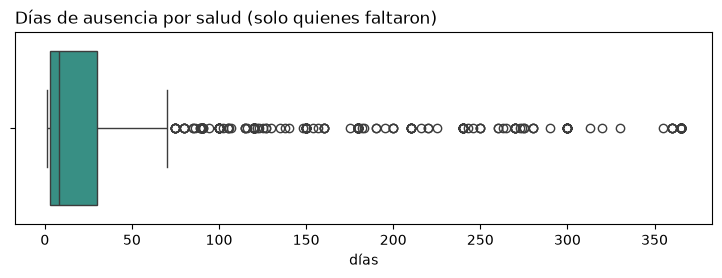

In [58]:
dias_faltaron = limpio[limpio["ausencia"] == 1]["dias"].dropna()

q1 = dias_faltaron.quantile(0.25)
q3 = dias_faltaron.quantile(0.75)
iqr = q3 - q1
limite = q3 + 1.5 * iqr
outliers = dias_faltaron[dias_faltaron > limite]

print("Q1 =", q1, "días | Q3 =", q3, "días | IQR =", iqr, "| límite =", limite, "días")
print("Outliers:", len(outliers), "personas, de", outliers.min(), "a", outliers.max(), "días")

fig, ax = plt.subplots(figsize=(9, 2.5))
sns.boxplot(x=dias_faltaron, color="#2A9D8F", ax=ax)
ax.set_title("Días de ausencia por salud (solo quienes faltaron)", loc="left")
ax.set_xlabel("días")
plt.show()

Los datos atípicos son personas con **bajas largas** (de meses).

Justo es el grupo que me interesa para el estudio.

In [59]:
# Duplicados
print("Filas iguales:", limpio.duplicated().sum())
print("Personas repetidas (mismo hogar y mismo número de orden):", adultos.duplicated(subset=["IDENTHOGAR", "NORDENa"]).sum())

Filas iguales: 492
Personas repetidas (mismo hogar y mismo número de orden): 0


Hay filas iguales, pero son **personas distintas** que han contestado lo mismo (mismo sexo, edad, comunidad...). 
Un duplicado sería la misma persona dos veces -> (0).

Creación de:

- **Tramos:** agrupo la edad y los días de ausencia en tramos para poder comparar grupos.

- **Variables nuevas:**

"musculoesqueletico" = 1 si tiene dolor lumbar **o** cervical **o** artrosis

"salud_mental" = 1 si tiene depresión o ansiedad

In [60]:
# Tramos de edad (de menor a mayor: cada línea pisa a la anterior)
limpio["tramo_edad"] = None
limpio.loc[limpio["edad"] >= 16, "tramo_edad"] = "16-29"
limpio.loc[limpio["edad"] >= 30, "tramo_edad"] = "30-39"
limpio.loc[limpio["edad"] >= 40, "tramo_edad"] = "40-49"
limpio.loc[limpio["edad"] >= 50, "tramo_edad"] = "50-59"
limpio.loc[limpio["edad"] >= 60, "tramo_edad"] = "60 o más"

# Tramos de días de ausencia (igual, de menor a mayor)
limpio["tramo_dias"] = None
limpio.loc[limpio["dias"] >= 0, "tramo_dias"] = "0"
limpio.loc[limpio["dias"] >= 1, "tramo_dias"] = "1-3"
limpio.loc[limpio["dias"] >= 4, "tramo_dias"] = "4-14"
limpio.loc[limpio["dias"] >= 15, "tramo_dias"] = "15-60"
limpio.loc[limpio["dias"] >= 61, "tramo_dias"] = "Más de 60"

# Variables nuevas de salud
limpio["musculoesqueletico"] = limpio[["lumbar", "cervical", "artrosis"]].max(axis=1)
limpio["salud_mental"] = limpio[["depresion", "ansiedad"]].max(axis=1)

limpio["grupo_salud"] = "Ninguno"
limpio.loc[limpio["musculoesqueletico"] == 1, "grupo_salud"] = "Musculoesquelético"
limpio.loc[limpio["salud_mental"] == 1, "grupo_salud"] = "Salud mental"
limpio.loc[(limpio["musculoesqueletico"] == 1) & (limpio["salud_mental"] == 1), "grupo_salud"] = "Los dos"

print(limpio["grupo_salud"].value_counts())
limpio.head()

grupo_salud
Ninguno               7012
Musculoesquelético    1921
Los dos                529
Salud mental           413
Name: count, dtype: int64


,codigo_ccaa,sexo,edad,peso,ausencia,dias,lumbar,cervical,artrosis,depresion,ansiedad,tramo_edad,tramo_dias,musculoesqueletico,salud_mental,grupo_salud
5,16,Hombre,27,2023.054,1.0,5.0,0.0,0.0,0.0,0.0,0.0,16-29,4-14,0.0,0.0,Ninguno
9,16,Mujer,58,2926.400,1.0,250.0,0.0,0.0,0.0,0.0,0.0,50-59,Más de 60,0.0,0.0,Ninguno
10,16,Hombre,49,1790.319,0.0,0.0,1.0,0.0,0.0,0.0,0.0,40-49,0,1.0,0.0,Musculoesquelético
11,16,Hombre,45,1790.319,1.0,40.0,0.0,0.0,1.0,0.0,0.0,40-49,15-60,1.0,0.0,Musculoesquelético
13,16,Hombre,64,652.231,1.0,3.0,1.0,1.0,0.0,0.0,0.0,60 o más,1-3,1.0,0.0,Musculoesquelético


In [61]:
# Guardo
limpio.to_csv(LIMPIOS + "encuesta_ocupados.csv", index=False)
print("Guardado encuesta_ocupados.csv:", limpio.shape)

Guardado encuesta_ocupados.csv: (9875, 16)


### 4. Seguridad Social, Incapacidad Temporal (2023-2025)

Cargo los tres años y los junto en una sola tabla. Los tres archivos tienen las mismas columnas.

In [62]:
tablas_it = []                                     # en [] guardo la tabla de cada año
for anio in [2023, 2024, 2025]:
    tabla_anio = pd.read_excel(RAW + "IT_cierre_anual_" + str(anio) + ".xlsx", sheet_name=1)   # la segunda hoja: los datos
    print(anio, "->", tabla_anio.shape)
    tablas_it.append(tabla_anio)

it = pd.concat(tablas_it, ignore_index=True)       # una debajo de otra; ignore_index: numera las filas de nuevo
print("Todo junto:", it.shape)
it.head()

2023 -> (13525, 9)
2024 -> (12342, 9)
2025 -> (12975, 9)
Todo junto: (38842, 9)


,Ejercicio,Mes,Organismo,Régimen,Contingencia,Sexo,Provincia,Indicador,Suma de Cantidad
0,2023,Cierre,Agregado de M.C.S.S.,RÉGIMEN ESPECIAL DE TRABAJADORES DEL MAR,CONTINGENCIAS COMUNES,HOMBRES,ALICANTE/ALACANT,19,298.0
1,2023,Cierre,Agregado de M.C.S.S.,RÉGIMEN ESPECIAL DE TRABAJADORES DEL MAR,CONTINGENCIAS COMUNES,HOMBRES,ALICANTE/ALACANT,20,15690.0
2,2023,Cierre,Agregado de M.C.S.S.,RÉGIMEN ESPECIAL DE TRABAJADORES DEL MAR,CONTINGENCIAS COMUNES,HOMBRES,ALICANTE/ALACANT,21,73.0
3,2023,Cierre,Agregado de M.C.S.S.,RÉGIMEN ESPECIAL DE TRABAJADORES DEL MAR,CONTINGENCIAS COMUNES,HOMBRES,ALICANTE/ALACANT,22,1622.0
4,2023,Cierre,Agregado de M.C.S.S.,RÉGIMEN ESPECIAL DE TRABAJADORES DEL MAR,CONTINGENCIAS COMUNES,HOMBRES,ALICANTE/ALACANT,25,323.0


### Formato
- **Mes:** solo quiero el **cierre** del año (el total). Por si viene escrito en mayúscula o minúscula, lo paso a minúscula con ".str.lower()" antes de comparar.
- **Sexo:** unifico "HOMBRE" → "HOMBRES" y "MUJER" → "MUJERES".
- **Indicador:** cambio el número por un nombre, con un diccionario y ".map()".

In [63]:
it = it[it["Mes"].str.lower() == "cierre"]  # variable incapacidad temporal
it["Sexo"] = it["Sexo"].replace({"HOMBRE": "HOMBRES", "MUJER": "MUJERES"})

nombres_indicadores = {19: "finalizadas", 20: "dias", 21: "abiertas", 22: "trabajadores_final",
                       25: "iniciadas", 26: "trabajadores_medios"}
it["indicador"] = it["Indicador"].map(nombres_indicadores)

print(it["Sexo"].value_counts())
print()
print(it["indicador"].value_counts())

Sexo
SIN DETERMINAR    14761
HOMBRES           12311
MUJERES           11770
Name: count, dtype: int64

indicador
finalizadas            7247
dias                   7247
iniciadas              7247
abiertas               6598
trabajadores_final     5717
trabajadores_medios    4786
Name: count, dtype: int64


In [64]:
# Missings y duplicados

print("Vacíos por columna:")
print(it.isna().sum())
print()
print("Filas duplicadas:", it.duplicated().sum())

Vacíos por columna:
Ejercicio           0
Mes                 0
Organismo           0
Régimen             0
Contingencia        0
Sexo                0
Provincia           0
Indicador           0
Suma de Cantidad    0
indicador           0
dtype: int64

Filas duplicadas: 2136


No hay vacíos.

Hay filas iguales, pero **no las quito**. El archivo tiene un desglose que no viene en ninguna columna, así que hay varias filas con las mismas etiquetas, y la propia hoja Estadística de la Seguridad Social **las suma todas**. Lo compruebo sumando todas las filas, tienen que salir los totales oficiales de la hoja Estadística («Total general»: 9.891.078 bajas iniciadas en 2025).

In [65]:
iniciadas_2025 = it[(it["Ejercicio"] == 2025) & (it["indicador"] == "iniciadas")]["Suma de Cantidad"].sum()
print("Bajas iniciadas en 2025 sumando todas las filas:", iniciadas_2025, "| Total oficial: 9891078")

Bajas iniciadas en 2025 sumando todas las filas: 9891078.0 | Total oficial: 9891078


Coincide: si quitara las filas repetidas, perdería bajas de verdad.

Continúo: hay una fila por organismo, régimen y sexo. Quiero **una fila por año, provincia y contingencia**, con cada indicador en una columna. Realizo "pivot_table" que **suma** (aggfunc="sum") todo lo que tenga el mismo año, provincia y contingencia. Las columnas que no pongo (organismo, régimen, sexo) se suman juntas y desaparecen: así quito las columnas que no necesito.

In [66]:
it_provincias = it.pivot_table(index=["Ejercicio", "Provincia", "Contingencia"], columns="indicador",
                               values="Suma de Cantidad", aggfunc="sum").reset_index()
it_provincias.columns.name = None
it_provincias = it_provincias.rename(columns={"Ejercicio": "anio", "Provincia": "provincia"})
it_provincias["contingencia"] = it_provincias["Contingencia"].map({"CONTINGENCIAS COMUNES": "comunes",
                                                                   "CONTINGENCIAS PROFESIONALES": "profesionales"})
it_provincias = it_provincias.drop(columns=["Contingencia"])
print(it_provincias.shape, "-> 3 años x 52 provincias x 2 contingencias")
it_provincias.head()

(312, 9) -> 3 años x 52 provincias x 2 contingencias


,anio,provincia,abiertas,dias,finalizadas,iniciadas,trabajadores_final,trabajadores_medios,contingencia
0,2023,ALBACETE,7221.0,2196990.0,37580.0,39333.0,157647.0,159012.916667,comunes
1,2023,ALBACETE,599.0,241471.0,6023.0,6011.0,148261.0,150615.000000,profesionales
2,2023,ALICANTE/ALACANT,32555.0,9861357.0,192504.0,199252.0,760831.0,756238.166667,comunes
3,2023,ALICANTE/ALACANT,2824.0,1076861.0,24544.0,24580.0,718441.0,716634.166667,profesionales
4,2023,ALMERÍA,13003.0,4353791.0,68745.0,71699.0,345443.0,338770.000000,comunes


Calculo de los datos de la Seguridad Social
- **Incidencia** = bajas que empiezan **al mes** por cada 1.000 trabajadores = iniciadas / 12 / trabajadores medios × 1.000
- **Duración media** = días de baja / bajas que terminaron → cuántos días dura una baja de media
- **Prevalencia** = bajas abiertas el último día / trabajadores × 1.000 → de cada 1.000 trabajadores, cuántos están de baja en un día cualquiera

In [67]:
it_provincias["incidencia"] = (it_provincias["iniciadas"] / 12 / it_provincias["trabajadores_medios"] * 1000).round(2)
it_provincias["duracion"] = (it_provincias["dias"] / it_provincias["finalizadas"]).round(1)
it_provincias["prevalencia"] = (it_provincias["abiertas"] / it_provincias["trabajadores_final"] * 1000).round(2)
it_provincias[it_provincias["contingencia"] == "comunes"].head()

,anio,provincia,abiertas,dias,finalizadas,iniciadas,trabajadores_final,trabajadores_medios,contingencia,incidencia,duracion,prevalencia
0,2023,ALBACETE,7221.0,2196990.0,37580.0,39333.0,157647.0,159012.916667,comunes,20.61,58.5,45.80
2,2023,ALICANTE/ALACANT,32555.0,9861357.0,192504.0,199252.0,760831.0,756238.166667,comunes,21.96,51.2,42.79
4,2023,ALMERÍA,13003.0,4353791.0,68745.0,71699.0,345443.0,338770.000000,comunes,17.64,63.3,37.64
6,2023,ARABA/ÁLAVA,9643.0,3040730.0,86346.0,88817.0,170066.0,169038.500000,comunes,43.79,35.2,56.70
8,2023,ASTURIAS,22968.0,6533254.0,103010.0,109055.0,394407.0,393053.666667,comunes,23.12,63.4,58.23


Para cruzar con el INE y con la Encuesta necesito la **comunidad**. 
Mediante un diccionario que dice a qué comunidad pertenece cada provincia, con los **mismos números** que usan el INE y la Encuesta (1 = Andalucía... 16 = País Vasco).

In [68]:
provincia_a_ccaa = {
    "ALMERÍA": 1, "CÁDIZ": 1, "CÓRDOBA": 1, "GRANADA": 1, "HUELVA": 1, "JAÉN": 1, "MÁLAGA": 1, "SEVILLA": 1,   # 1 Andalucía
    "HUESCA": 2, "TERUEL": 2, "ZARAGOZA": 2,                                                                # 2 Aragón
    "ASTURIAS": 3,                                                                                          # 3 Asturias
    "ILLES BALEARES": 4,                                                                                    # 4 Baleares
    "PALMAS (LAS)": 5, "SANTA CRUZ DE TENERIFE": 5,                                                         # 5 Canarias
    "CANTABRIA": 6,                                                                                         # 6 Cantabria
    "ÁVILA": 7, "BURGOS": 7, "LEÓN": 7, "PALENCIA": 7, "SALAMANCA": 7, "SEGOVIA": 7, "SORIA": 7,
    "VALLADOLID": 7, "ZAMORA": 7,                                                                           # 7 Castilla y León
    "ALBACETE": 8, "CIUDAD REAL": 8, "CUENCA": 8, "GUADALAJARA": 8, "TOLEDO": 8,                            # 8 Castilla-La Mancha
    "BARCELONA": 9, "GIRONA": 9, "LLEIDA": 9, "TARRAGONA": 9,                                               # 9 Cataluña
    "ALICANTE/ALACANT": 10, "CASTELLÓN/CASTELLÓ": 10, "VALENCIA/VALÈNCIA": 10,                              # 10 C. Valenciana
    "BADAJOZ": 11, "CÁCERES": 11,                                                                           # 11 Extremadura
    "CORUÑA (A)": 12, "LUGO": 12, "OURENSE": 12, "PONTEVEDRA": 12,                                          # 12 Galicia
    "MADRID": 13,                                                                                           # 13 Madrid
    "MURCIA": 14,                                                                                           # 14 Murcia
    "NAVARRA": 15,                                                                                          # 15 Navarra
    "ARABA/ÁLAVA": 16, "BIZKAIA": 16, "GIPUZKOA": 16,                                                       # 16 País Vasco
    "RIOJA (LA)": 17,                                                                                       # 17 La Rioja
    "CEUTA": 18, "MELILLA": 19,                                                                             # 18 Ceuta y 19 Melilla
}

In [69]:
it_provincias["codigo_ccaa"] = it_provincias["provincia"].map(provincia_a_ccaa)
print("Provincias sin comunidad:", it_provincias["codigo_ccaa"].isna().sum(), "(tiene que salir 0)")

it_provincias.to_csv(LIMPIOS + "it_provincias.csv", index=False)
print("Guardado it_provincias.csv:", it_provincias.shape)

Provincias sin comunidad: 0 (tiene que salir 0)
Guardado it_provincias.csv: (312, 13)


En relacion a las provincias de cada comunidad, no hago la media de las tasas de cada provincia, porque una provincia pequeña contaría igual que una grande. 
Sumo las bajas y los trabajadores de la comunidad y calculo de nuevo las tasas.

In [70]:
it_ccaa = it_provincias.groupby(["anio", "contingencia", "codigo_ccaa"])[
    ["iniciadas", "finalizadas", "dias", "abiertas", "trabajadores_medios", "trabajadores_final"]].sum().reset_index()
it_ccaa["incidencia"] = (it_ccaa["iniciadas"] / 12 / it_ccaa["trabajadores_medios"] * 1000).round(2)
it_ccaa["duracion"] = (it_ccaa["dias"] / it_ccaa["finalizadas"]).round(1)
it_ccaa["prevalencia"] = (it_ccaa["abiertas"] / it_ccaa["trabajadores_final"] * 1000).round(2)

# y lo mismo para toda España
it_espana = it_provincias.groupby(["anio", "contingencia"])[
    ["iniciadas", "finalizadas", "dias", "abiertas", "trabajadores_medios", "trabajadores_final"]].sum().reset_index()
it_espana["incidencia"] = (it_espana["iniciadas"] / 12 / it_espana["trabajadores_medios"] * 1000).round(2)
it_espana["duracion"] = (it_espana["dias"] / it_espana["finalizadas"]).round(1)
it_espana["prevalencia"] = (it_espana["abiertas"] / it_espana["trabajadores_final"] * 1000).round(2)
it_espana.to_csv(LIMPIOS + "it_espana.csv", index=False)
it_espana

,anio,contingencia,iniciadas,finalizadas,dias,abiertas,trabajadores_medios,trabajadores_final,incidencia,duracion,prevalencia
0,2023,comunes,8150921.0,7900305.0,311937060.0,1029602.0,2.149569e+07,2.166545e+07,31.60,39.5,47.52
1,2023,profesionales,829262.0,833611.0,33208926.0,83442.0,2.000974e+07,2.013541e+07,3.45,39.8,4.14
2,2024,comunes,8552266.0,8370019.0,360968214.0,1094084.0,2.207024e+07,2.219544e+07,32.29,43.1,49.29
3,2024,profesionales,710348.0,705442.0,32130539.0,88152.0,2.078133e+07,2.087860e+07,2.85,45.5,4.22
4,2025,comunes,9196228.0,9008569.0,381455328.0,1163815.0,2.252190e+07,2.263244e+07,34.03,42.3,51.42
5,2025,profesionales,694850.0,698898.0,32846790.0,84445.0,2.134629e+07,2.132667e+07,2.71,47.0,3.96


Las bajas por **enfermedad común** (contingencias comunes) son muchísimas más que las de accidente de trabajo y **suben cada año**. 
Dato que el INE no aporta.

Las cuatro fuentes de datos tienen en común: la **comunidad autónoma**, con el mismo número. Así que hago **una sola tabla con una fila por comunidad** y, en columnas, lo que dice cada fuente.

In [71]:
# 1) Seguridad Social: 2025, enfermedad común. Esta tabla tiene las 19 comunidades y ciudades autónomas
tabla_comun = it_ccaa[(it_ccaa["anio"] == 2025) & (it_ccaa["contingencia"] == "comunes")][
    ["codigo_ccaa", "incidencia", "duracion", "prevalencia"]]

# 2) INE: media de los últimos 4 trimestres por comunidad (sector total)
ultima_fecha = ine_ancho["fecha"].max()
ine_ultimo_anio = ine_ancho[(ine_ancho["sector"] == "Total") & (ine_ancho["codigo_ccaa"] > 0)
                           & (ine_ancho["fecha"] > ultima_fecha - pd.DateOffset(months=12))]
ine_ccaa = ine_ultimo_anio.groupby(["codigo_ccaa", "ccaa"])["tasa_nt"].mean().round(2).reset_index()

# 3) Encuesta: % ponderados por comunidad
encuesta_ccaa = pd.DataFrame({"codigo_ccaa": sorted(limpio["codigo_ccaa"].unique())})
for variable in ["ausencia", "musculoesqueletico", "salud_mental"]:
    datos = limpio.dropna(subset=[variable])
    suma_valor_por_peso = (datos[variable] * datos["peso"]).groupby(datos["codigo_ccaa"]).sum()
    suma_pesos = datos["peso"].groupby(datos["codigo_ccaa"]).sum()
    encuesta_ccaa["pct_" + variable] = (suma_valor_por_peso / suma_pesos * 100).round(1).values
datos = limpio.dropna(subset=["dias"])
dias_medios = (datos["dias"] * datos["peso"]).groupby(datos["codigo_ccaa"]).sum() / datos["peso"].groupby(datos["codigo_ccaa"]).sum()
encuesta_ccaa["dias_medios"] = dias_medios.round(1).values

# 4) Junto todo con merge, siempre por codigo_ccaa
tabla_comun = tabla_comun.merge(ine_ccaa, on="codigo_ccaa", how="left")
tabla_comun = tabla_comun.merge(encuesta_ccaa, on="codigo_ccaa", how="left")
print("Filas:", len(tabla_comun))
tabla_comun

Filas: 19


,codigo_ccaa,incidencia,duracion,prevalencia,ccaa,tasa_nt,pct_ausencia,pct_musculoesqueletico,pct_salud_mental,dias_medios
0,1,26.07,52.1,44.93,Andalucía,15.62,22.0,21.1,6.7,8.4
1,2,31.42,46.9,53.07,Aragón,17.16,27.0,24.3,8.6,8.2
2,3,24.43,69.7,61.72,"Asturias, Principado de",18.35,24.4,33.5,14.0,10.0
3,4,35.66,31.4,43.72,"Balears, Illes",14.14,31.0,33.5,13.1,10.5
4,5,42.02,47.1,70.56,Canarias,17.29,23.6,25.4,7.8,11.5
5,6,33.72,52.1,62.41,Cantabria,17.41,27.6,27.8,11.4,11.5
6,7,25.11,58.2,52.42,Castilla y León,16.95,28.0,27.8,8.3,12.4
7,8,30.32,46.9,51.45,Castilla - La Mancha,15.85,25.8,23.3,8.6,10.2
8,9,49.11,28.5,51.60,Cataluña,17.02,26.9,18.5,9.2,7.2
9,10,24.95,54.4,49.94,Comunitat Valenciana,16.53,29.9,19.6,11.5,6.9


Una tabla de 19 filas. 

Ceuta y Melilla (códigos 18 y 19) tienen **vacíos** en las columnas del INE, porque el INE no da su dato en esta tabla. Es un missing que **sale al juntar** las tablas: no es un error, es que esa fuente no tiene el dato.

Como solo son dos ciudades y me faltan datos de una fuente, me quedo con las **17 comunidades** que tienen todo. 

In [72]:
print("Vacíos por columna:")
print(tabla_comun.isna().sum())

tabla_comun = tabla_comun.dropna(subset=["tasa_nt"]).copy()
tabla_comun["ccaa"] = tabla_comun["ccaa"].replace({
    "Asturias, Principado de": "Asturias", "Balears, Illes": "Baleares", "Navarra, Comunidad Foral de": "Navarra",
    "Madrid, Comunidad de": "Madrid", "Murcia, Región de": "Murcia", "Rioja, La": "La Rioja",
    "Comunitat Valenciana": "C. Valenciana", "Castilla - La Mancha": "Castilla-La Mancha"})
print("Comunidades con todas las fuentes:", len(tabla_comun))

Vacíos por columna:
codigo_ccaa               0
incidencia                0
duracion                  0
prevalencia               0
ccaa                      2
tasa_nt                   2
pct_ausencia              0
pct_musculoesqueletico    0
pct_salud_mental          0
dias_medios               0
dtype: int64
Comunidades con todas las fuentes: 17


Las tres fuentes miden cosas distintas: el INE da un **% de horas no trabajadas**, la Seguridad Social los **trabajadores de baja por cada 1.000** y la Encuesta el **% de personas que faltó por salud**. Con escalas tan diferentes no puedo compararlas directamente.

Por eso paso las tres a una misma escala de 0 a 1. En cada medida, la comunidad con el valor más bajo queda en **0**, la del valor más alto en **1** y el resto entre medias. La fórmula es:

(valor − mínimo) / (máximo − mínimo)

Por ejemplo, en la prevalencia Madrid (42,2) queda en 0 y Canarias (70,6) en 1. Una comunidad con 0,5 está justo a mitad de camino.

Lo hago una medida detrás de otra y guardo el resultado en columnas nuevas que terminan en "_0a1" («de 0 a 1»), para que las columnas originales se queden igual. Así puedo poner las tres fuentes en la misma gráfica y ver si una comunidad sale alta en todas o solo en una.

Al final guardo la tabla común en "tabla_comun_ccaa.csv", en la carpeta "processed".

In [73]:
# Escalado de 0 a 1 (min-max): el valor más bajo queda en 0 y el más alto en 1

# INE: horas no trabajadas
minimo = tabla_comun["tasa_nt"].min()
maximo = tabla_comun["tasa_nt"].max()
tabla_comun["tasa_nt_0a1"] = ((tabla_comun["tasa_nt"] - minimo) / (maximo - minimo)).round(2)

# Seguridad Social: trabajadores de baja por 1.000
minimo = tabla_comun["prevalencia"].min()
maximo = tabla_comun["prevalencia"].max()
tabla_comun["prevalencia_0a1"] = ((tabla_comun["prevalencia"] - minimo) / (maximo - minimo)).round(2)

# Encuesta: % que faltó por salud
minimo = tabla_comun["pct_ausencia"].min()
maximo = tabla_comun["pct_ausencia"].max()
tabla_comun["pct_ausencia_0a1"] = ((tabla_comun["pct_ausencia"] - minimo) / (maximo - minimo)).round(2)

tabla_comun.to_csv(LIMPIOS + "tabla_comun_ccaa.csv", index=False)
tabla_comun.sort_values("prevalencia", ascending=False)

,codigo_ccaa,incidencia,duracion,prevalencia,ccaa,tasa_nt,pct_ausencia,pct_musculoesqueletico,pct_salud_mental,dias_medios,tasa_nt_0a1,prevalencia_0a1,pct_ausencia_0a1
4,5,42.02,47.1,70.56,Canarias,17.29,23.6,25.4,7.8,11.5,0.63,1.00,0.41
11,12,23.58,79.7,69.14,Galicia,18.01,27.6,34.1,10.5,14.1,0.78,0.95,0.61
15,16,43.18,41.3,62.68,País Vasco,19.12,29.7,32.8,9.0,10.6,1.00,0.72,0.71
5,6,33.72,52.1,62.41,Cantabria,17.41,27.6,27.8,11.4,11.5,0.66,0.71,0.61
2,3,24.43,69.7,61.72,Asturias,18.35,24.4,33.5,14.0,10.0,0.85,0.69,0.45
13,14,31.06,55.0,61.19,Murcia,17.80,23.4,20.3,10.5,10.4,0.73,0.67,0.40
10,11,17.77,84.5,58.07,Extremadura,16.05,15.1,15.1,4.0,4.6,0.38,0.56,0.00
1,2,31.42,46.9,53.07,Aragón,17.16,27.0,24.3,8.6,8.2,0.61,0.38,0.58
6,7,25.11,58.2,52.42,Castilla y León,16.95,28.0,27.8,8.3,12.4,0.56,0.36,0.63
8,9,49.11,28.5,51.60,Cataluña,17.02,26.9,18.5,9.2,7.2,0.58,0.33,0.58


El INE y los accidentes comparten el **sector**. Hago una tabla con los tres sectores que están en las dos fuentes (el sector agrario no está en el INE).

In [74]:
ine_sector = ine_ancho[(ine_ancho["codigo_ccaa"] == 0) & (ine_ancho["sector"] != "Total") & (ine_ancho["anio"] == 2025)]
ine_sector = ine_sector.groupby("sector")["tasa_nt"].mean().round(1).reset_index()

accidentes_sector = accidentes.groupby("sector")["accidentes"].sum().reset_index()
sobreesfuerzo = accidentes[accidentes["forma"].str.startswith("Sobreesfuerzo")][["sector", "accidentes"]]
sobreesfuerzo = sobreesfuerzo.rename(columns={"accidentes": "sobreesfuerzos"})

tabla_sector = ine_sector.merge(accidentes_sector, on="sector").merge(sobreesfuerzo, on="sector").merge(
    recaidas[["sector", "tasa_recaida"]], on="sector")
tabla_sector["pct_sobreesfuerzo"] = (tabla_sector["sobreesfuerzos"] / tabla_sector["accidentes"] * 100).round(1)
tabla_sector.to_csv(LIMPIOS + "tabla_comun_sector.csv", index=False)
tabla_sector

,sector,tasa_nt,accidentes,sobreesfuerzos,tasa_recaida,pct_sobreesfuerzo
0,Construcción,15.0,82274,21136,3.3,25.7
1,Industria,18.0,108790,30650,4.6,28.2
2,Servicios,16.1,325720,94437,3.6,29.0


El sector de la Industria refleja más horas no trabajadas, más sobreesfuerzos y más recaídas. 

In [75]:
for archivo in sorted(os.listdir(LIMPIOS)):
    tabla = pd.read_csv(LIMPIOS + archivo)
    print(archivo, "->", tabla.shape[0], "filas y", tabla.shape[1], "columnas")

# después de limpiar los datos

accidentes_limpio.csv -> 44 filas y 3 columnas
encuesta_ocupados.csv -> 9875 filas y 16 columnas
ine_limpio.csv -> 5328 filas y 9 columnas
it_espana.csv -> 6 filas y 11 columnas
it_provincias.csv -> 312 filas y 13 columnas
recaidas_limpio.csv -> 4 filas y 4 columnas
tabla_comun_ccaa.csv -> 17 filas y 13 columnas
tabla_comun_sector.csv -> 3 filas y 6 columnas


## Análisis univariante

In [76]:
# COLORES:
COLOR_PRINCIPAL = "#00868B"    # turquesa oscuro: el color normal de las barras y líneas
COLOR_DESTACADO = "#F2937D"    # coral suave (menos intenso): lo que quiero que se vea primero
COLOR_SUAVE = "#B8E2DE"        # verde azulado agua, claro: lo que está de fondo
COLORES_GRUPOS = ["#D7263D", "#4876FF", "#8FD98F", "#8B1C62"]   # rojo, azul real, verde claro suave, granate (uno por grupo, en orden)
MAPA_DE_CALOR = "Blues"         # degradado para los heatmaps

sns.set_theme(style="whitegrid")     # fondo blanco con cuadrícula suave

ine = pd.read_csv(LIMPIOS + "ine_limpio.csv", parse_dates=["fecha"])
accidentes = pd.read_csv(LIMPIOS + "accidentes_limpio.csv")
recaidas = pd.read_csv(LIMPIOS + "recaidas_limpio.csv")
encuesta = pd.read_csv(LIMPIOS + "encuesta_ocupados.csv")
it_provincias = pd.read_csv(LIMPIOS + "it_provincias.csv")
it_espana = pd.read_csv(LIMPIOS + "it_espana.csv")
comunidades = pd.read_csv(LIMPIOS + "tabla_comun_ccaa.csv")      # la tabla común: una fila por comunidad
sectores_comun = pd.read_csv(LIMPIOS + "tabla_comun_sector.csv")
print("INE:", ine.shape, "| Accidentes:", accidentes.shape, "| Recaídas:", recaidas.shape,
      "| Encuesta:", encuesta.shape, "| Seguridad Social:", it_provincias.shape, "| Tabla común:", comunidades.shape)

INE: (5328, 9) | Accidentes: (44, 3) | Recaídas: (4, 4) | Encuesta: (9875, 16) | Seguridad Social: (312, 13) | Tabla común: (17, 13)


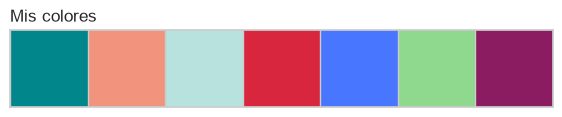

In [77]:
sns.palplot([COLOR_PRINCIPAL, COLOR_DESTACADO, COLOR_SUAVE] + COLORES_GRUPOS)
plt.title("Mis colores", loc="left")
plt.show()

Dias de ausencia por salud

In [78]:
# numerica
dias = encuesta[encuesta["ausencia"] == 1]["dias"].dropna()

medidas = pd.Series({
    "personas": len(dias),
    "media": dias.mean(),
    "mediana": dias.median(),
    "moda": dias.mode()[0],
    "Q1 (percentil 25)": dias.quantile(0.25),
    "Q3 (percentil 75)": dias.quantile(0.75),
    "percentil 90": dias.quantile(0.90),
    "mínimo": dias.min(),
    "máximo": dias.max(),
    "rango (máximo - mínimo)": dias.max() - dias.min(),
    "varianza": dias.var(),
    "desviación estándar (SD)": dias.std(),
    "IQR (Q3 - Q1)": dias.quantile(0.75) - dias.quantile(0.25),
    "asimetría": dias.skew(), # asimetria
})
medidas.round(1).to_frame("días de ausencia")

,días de ausencia
personas,2293.0
media,40.5
mediana,8.0
moda,2.0
Q1 (percentil 25),3.0
Q3 (percentil 75),30.0
percentil 90,120.0
mínimo,1.0
máximo,365.0
rango (máximo - mínimo),364.0


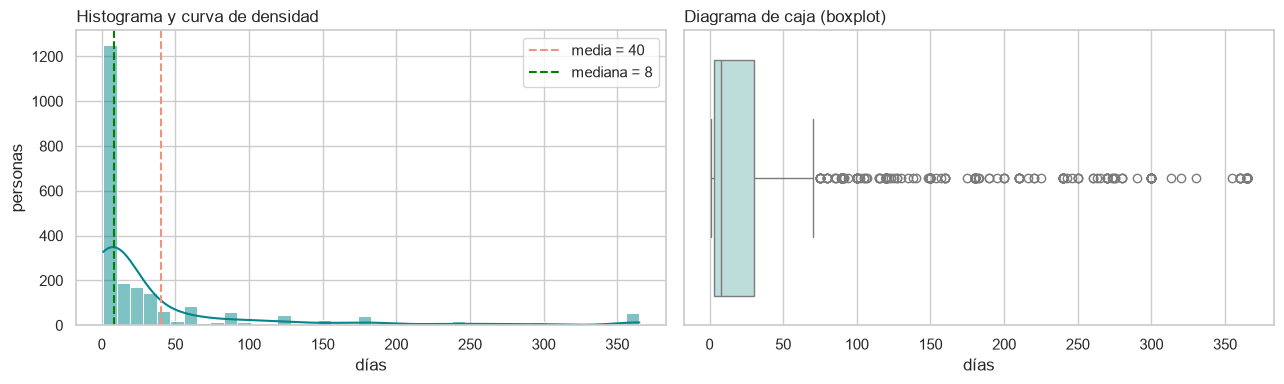

In [79]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(dias, bins=40, kde=True, color=COLOR_PRINCIPAL, ax=ejes[0])                 # <- color del histograma
ejes[0].axvline(dias.mean(), color=COLOR_DESTACADO, linestyle="--", label="media = " + str(round(dias.mean())))
ejes[0].axvline(dias.median(), color="green", linestyle="--", label="mediana = " + str(round(dias.median())))
ejes[0].set_title("Histograma y curva de densidad", loc="left")
ejes[0].set_xlabel("días")
ejes[0].set_ylabel("personas")
ejes[0].legend()

sns.boxplot(x=dias, color=COLOR_SUAVE, ax=ejes[1])                                       # <- color del boxplot
ejes[1].set_title("Diagrama de caja (boxplot)", loc="left")
ejes[1].set_xlabel("días")

plt.tight_layout()
plt.show()


- **Histograma:** cada barra cuenta cuántas personas hay en ese tramo de días. La línea (curva de densidad, "kde=True") es la misma forma suavizada.
- **Boxplot:** la caja va de Q1 a Q3 (el 50 % de la gente del medio), la raya de dentro es la mediana, los «bigotes» llegan hasta 1,5 × IQR y los puntos sueltos son los **outliers** (aquí, las bajas largas).

Se evidencia que la mitad de la gente que faltó lo hizo **8 días o menos** (mediana), pero la media sube a **40 días** porque hay un grupo con bajas muy largas: el 10 % pasa de 120 días y el máximo es un año entero. Por eso me interesa mirar ese grupo de bajas largas.

Edad de los ocupados

count    9875.0
mean       45.1
std        11.3
min        16.0
25%        37.0
50%        46.0
75%        54.0
max        86.0
Name: edad, dtype: float64
Asimetría: -0.17


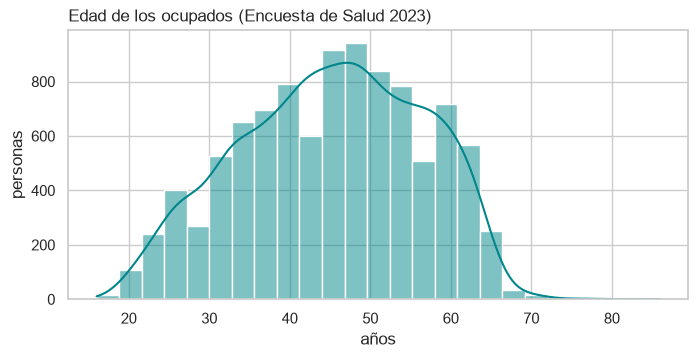

In [80]:
# numerica
print(encuesta["edad"].describe().round(1))
print("Asimetría:", round(encuesta["edad"].skew(), 2)) # asimetria

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(encuesta["edad"], bins=25, kde=True, color=COLOR_PRINCIPAL, ax=ax)          # <- color
ax.set_title("Edad de los ocupados (Encuesta de Salud 2023)", loc="left")
ax.set_xlabel("años")
ax.set_ylabel("personas")
plt.show()

La edad es bastante simetrica (media y mediana casi iguales)

Justo lo contrario que los días de baja. 

La mayoría de los ocupados tiene entre 37 y 54 años.


¿Cuánta gente faltó al trabajo por salud?

In [81]:
# categorica
con_respuesta = encuesta.dropna(subset=["ausencia"])

sin_ponderar = con_respuesta["ausencia"].mean() * 100
ponderado = (con_respuesta["ausencia"] * con_respuesta["peso"]).sum() / con_respuesta["peso"].sum() * 100

print("Faltó al trabajo por salud en el último año:")
print("- en la muestra:", round(sin_ponderar, 1), "%")
print("- en la población (ponderado):", round(ponderado, 1), "%")

# % ponderado = suma de los pesos de quien faltó / suma de todos los pesos × 100

# Los pesos son el factor de elevación del INE -> cuántas personas representa cada entrevistado. 
# Con ellos calculo porcentajes que representan a toda España, no solo a la muestra (renombrado).


Faltó al trabajo por salud en el último año:
- en la muestra: 26.0 %
- en la población (ponderado): 25.1 %


Días de ausencia en tramos (tabla de frecuencias)

,personas,%
tramo_dias,,
0,7251,76.0
1-3,705,7.4
4-14,618,6.5
15-60,601,6.3
Más de 60,369,3.9


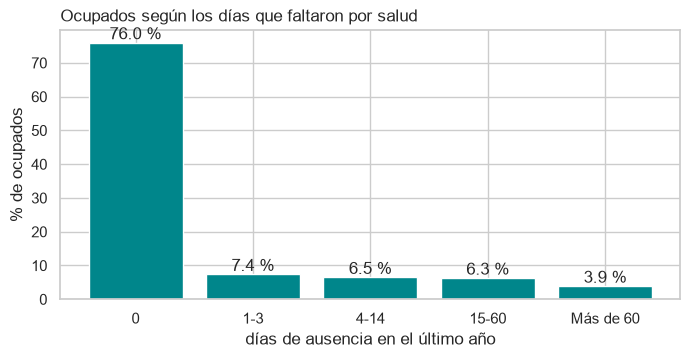

In [82]:
# categorica 
orden = ["0", "1-3", "4-14", "15-60", "Más de 60"]
frecuencias = encuesta["tramo_dias"].value_counts().reindex(orden)       # reindex: para que salgan en este orden
tabla = pd.DataFrame({"personas": frecuencias, "%": (frecuencias / frecuencias.sum() * 100).round(1)})
display(tabla)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(tabla.index, tabla["%"], color=COLOR_PRINCIPAL)                                   # <- color de las barras
for posicion, valor in enumerate(tabla["%"]):
    ax.text(posicion, valor + 1, str(valor) + " %", ha="center")                         # el número encima de cada barra
ax.set_title("Ocupados según los días que faltaron por salud", loc="left")
ax.set_xlabel("días de ausencia en el último año")
ax.set_ylabel("% de ocupados")
plt.show()

Sexo, edad y problemas de salud

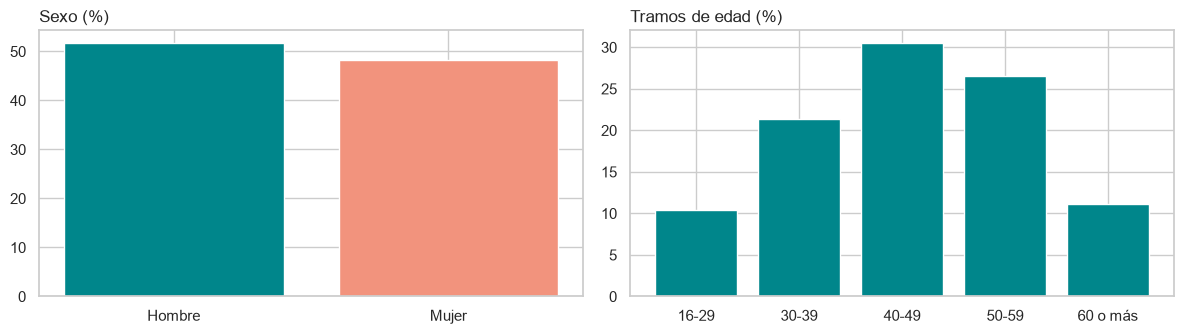

In [83]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))

pct_sexo = (encuesta["sexo"].value_counts(normalize=True) * 100).round(1)       # normalize=True: en proporción
ejes[0].bar(pct_sexo.index, pct_sexo.values, color=[COLOR_PRINCIPAL, COLOR_DESTACADO])   # <- un color por barra
ejes[0].set_title("Sexo (%)", loc="left")

pct_edad = (encuesta["tramo_edad"].value_counts(normalize=True).sort_index() * 100).round(1)
ejes[1].bar(pct_edad.index, pct_edad.values, color=COLOR_PRINCIPAL)                       # <- color
ejes[1].set_title("Tramos de edad (%)", loc="left")

plt.tight_layout()
plt.show()

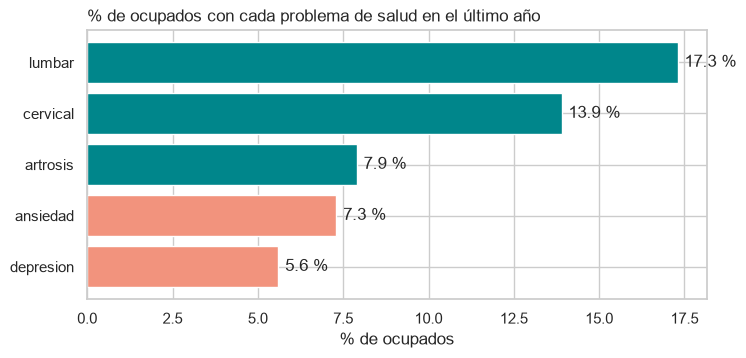

In [84]:
problemas = ["lumbar", "cervical", "artrosis", "depresion", "ansiedad"]
prevalencia = (encuesta[problemas].mean() * 100).round(1).sort_values()

colores_barras = [COLOR_DESTACADO if p in ["depresion", "ansiedad"] else COLOR_PRINCIPAL for p in prevalencia.index]


fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(prevalencia.index, prevalencia.values, color=colores_barras)       # barh = barras horizontales
for posicion, valor in enumerate(prevalencia.values):
    ax.text(valor + 0.2, posicion, str(valor) + " %", va="center")
ax.set_title("% de ocupados con cada problema de salud en el último año", loc="left")
ax.set_xlabel("% de ocupados")
plt.show()

Se observa que 1 de cada 4 ocupados (25,1 %, ponderado) faltó al trabajo por salud en el último año. Casi todas las ausencias son cortas, pero un 3,9 % faltó más de 60 días.

Hay casi los mismos hombres que mujeres, y la mayoría tiene entre 40 y 59 años.

Lo más frecuente es el **dolor de espalda** (lumbar 17,3 % y cervical 13,9 %), seguido de la artrosis, y en salud mental la ansiedad (7,3 %) y la depresión (5,6 %). 

Es justo donde más he intervenido en mi experiencia profesional como Terapeuta Ocupacional enfocado a la reincorporación laboral. 

INE: horas no trabajadas por comunidad y sector

Cojo el último año (4 trimestres). Uso **violín + swarm**:
- **violín** enseña la forma de la distribución: donde es ancho hay muchos datos
- **swarm** pinta **cada dato** como un punto.

Tasa de horas no trabajadas (% de las pactadas), comunidades, último año:
count    68.0
mean     16.9
std       3.4
min      12.0
25%      14.6
50%      16.1
75%      18.6
max      26.6
Name: tasa_nt, dtype: float64


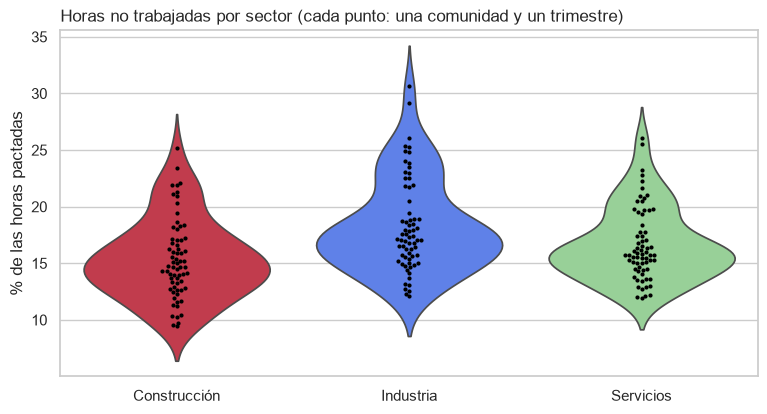

In [85]:
ultima_fecha = ine["fecha"].max()
ultimo_anio = ine[(ine["fecha"] > ultima_fecha - pd.DateOffset(months=12)) & (ine["codigo_ccaa"] > 0)]

print("Tasa de horas no trabajadas (% de las pactadas), comunidades, último año:")
print(ultimo_anio[ultimo_anio["sector"] == "Total"]["tasa_nt"].describe().round(1))

por_sector = ultimo_anio[ultimo_anio["sector"] != "Total"]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.violinplot(data=por_sector, x="sector", y="tasa_nt", hue="sector", palette=COLORES_GRUPOS[:3],
               inner=None, legend=False, ax=ax)                             
sns.swarmplot(data=por_sector, x="sector", y="tasa_nt", color="black", size=3, ax=ax)   
ax.set_title("Horas no trabajadas por sector (cada punto: una comunidad y un trimestre)", loc="left")
ax.set_xlabel("")
ax.set_ylabel("% de las horas pactadas")
plt.show()

Seguridad Social: las bajas médicas por provincia (2025, enfermedad común)


In [86]:
it_2025 = it_provincias[(it_provincias["anio"] == 2025) & (it_provincias["contingencia"] == "comunes")]
it_2025[["incidencia", "duracion", "prevalencia"]].describe().round(1)

,incidencia,duracion,prevalencia
count,52.0,52.0,52.0
mean,29.6,54.6,52.7
std,9.7,16.5,9.7
min,17.0,25.4,31.3
25%,21.4,42.9,44.0
50%,27.4,53.6,51.0
75%,35.5,65.2,59.9
max,51.4,93.8,73.2


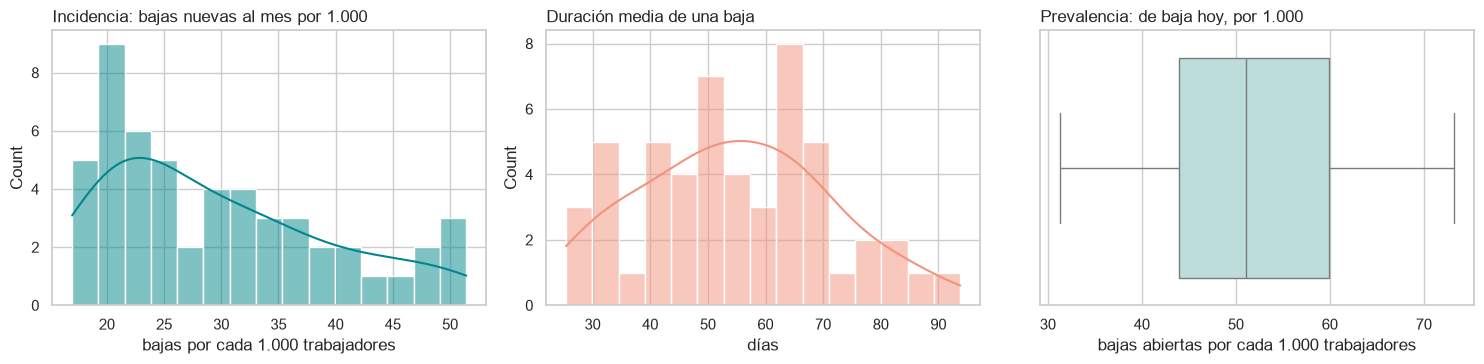

Las 3 provincias con más bajas nuevas:
       provincia  incidencia  duracion
274      NAVARRA       51.42      28.3
220    BARCELONA       50.92      27.8
250  GUADALAJARA       49.86      25.4

Las 3 provincias con bajas más largas:
    provincia  incidencia  duracion
264      LUGO       19.44      93.8
238   CÁCERES       16.96      85.5
218   BADAJOZ       18.23      84.1


In [87]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))

sns.histplot(it_2025["incidencia"], bins=15, kde=True, color=COLOR_PRINCIPAL, ax=ejes[0])        
ejes[0].set_title("Incidencia: bajas nuevas al mes por 1.000", loc="left")
ejes[0].set_xlabel("bajas por cada 1.000 trabajadores")

sns.histplot(it_2025["duracion"], bins=15, kde=True, color=COLOR_DESTACADO, ax=ejes[1])          
ejes[1].set_title("Duración media de una baja", loc="left")
ejes[1].set_xlabel("días")

sns.boxplot(x=it_2025["prevalencia"], color=COLOR_SUAVE, ax=ejes[2])                           
ejes[2].set_title("Prevalencia: de baja hoy, por 1.000", loc="left")
ejes[2].set_xlabel("bajas abiertas por cada 1.000 trabajadores")

plt.tight_layout()
plt.show()

print("Las 3 provincias con más bajas nuevas:")
print(it_2025.sort_values("incidencia", ascending=False)[["provincia", "incidencia", "duracion"]].head(3))
print()
print("Las 3 provincias con bajas más largas:")
print(it_2025.sort_values("duracion", ascending=False)[["provincia", "incidencia", "duracion"]].head(3))

Hay mucha diferencia entre provincias. En Navarra, Barcelona o Guadalajara empiezan unas **50 bajas al mes por cada 1.000 trabajadores**, pero duran poco (25-28 días). En Lugo, Cáceres o Badajoz empiezan menos de 20, pero duran **85-94 días**. Parece que hay dos tendencias: muchas cortas o pocas largas. 



Enfermedad común frente a accidente de trabajo (toda España, 2025):

               iniciadas  incidencia  duracion  prevalencia
contingencia                                               
comunes        9196228.0       34.03      42.3        51.42
profesionales   694850.0        2.71      47.0         3.96


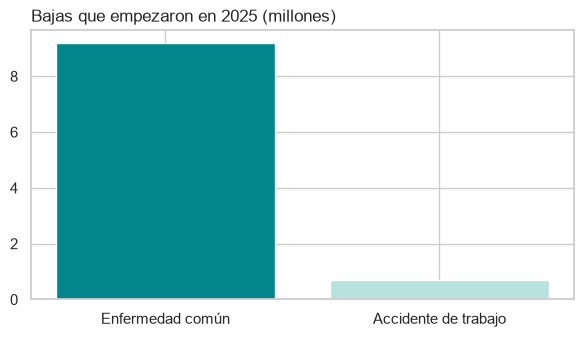

In [88]:
espana_2025 = it_espana[it_espana["anio"] == 2025].set_index("contingencia")
print(espana_2025[["iniciadas", "incidencia", "duracion", "prevalencia"]])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(["Enfermedad común", "Accidente de trabajo"], espana_2025["iniciadas"] / 1000000,
       color=[COLOR_PRINCIPAL, COLOR_SUAVE])                                                        # <- un color por barra
ax.set_title("Bajas que empezaron en 2025 (millones)", loc="left")
plt.show()

En 2025 empezaron **9,2 millones de bajas por enfermedad común** y unas 700.000 por accidente de trabajo. Las bajas por salud del día a día son más del 90 %: por eso en la tabla común uso la enfermedad común.

Accidentes ¿Cómo se producen?

,accidentes,%
forma,,
"Golpe contra un objeto inmóvil, trabajador en movimiento",152653,28.1
"Sobreesfuerzo, trauma psíquico, radiaciones, ruido, etc.",152171,28.0
"Choque o golpe contra un objeto en movimiento, colisión con",98180,18.0
"Contacto con agente material cortante, punzante, duro",61988,11.4
"Quedar atrapado, ser aplastado, sufrir una amputación",22389,4.1
"Contacto eléctrico, con fuego, temperaturas o sustancias peligrosas",22120,4.1
Accidentes de tráfico,20666,3.8
"Mordeduras, patadas, etc. (de animales o personas)",10678,2.0
Otra forma o contacto,1180,0.2


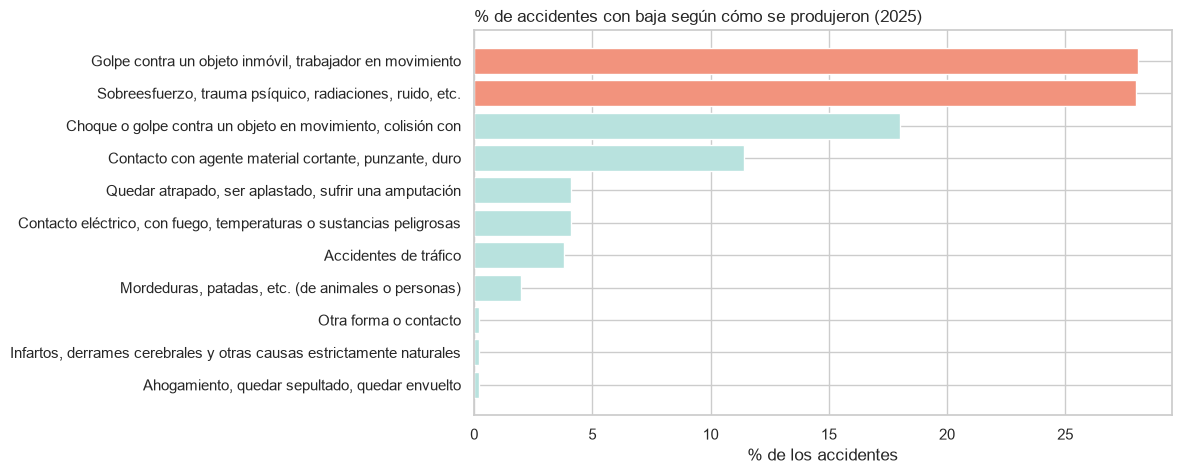

In [89]:
por_forma = accidentes.groupby("forma")["accidentes"].sum().sort_values()
pct_forma = (por_forma / por_forma.sum() * 100).round(1)
display(pd.DataFrame({"accidentes": por_forma, "%": pct_forma}).sort_values("accidentes", ascending=False))

colores_barras = [COLOR_SUAVE] * len(pct_forma)         
colores_barras[-1] = COLOR_DESTACADO                   
colores_barras[-2] = COLOR_DESTACADO

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(pct_forma.index, pct_forma.values, color=colores_barras)
ax.set_title("% de accidentes con baja según cómo se produjeron (2025)", loc="left")
ax.set_xlabel("% de los accidentes")
plt.show()

Hay dos formas muy similares, más de la mitad: **golpes contra objetos inmóviles (28,1 %)** y **sobreesfuerzos (28,0 %)**. 

Yo esperaba mayor los sobreesfuerzos. 

Los porcentajes son sobre los accidentes con forma conocida, porque quité «Sin información».

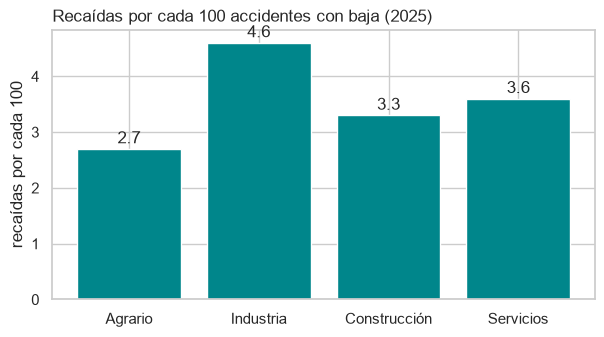

In [90]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(recaidas["sector"], recaidas["tasa_recaida"], color=COLOR_PRINCIPAL)              # <- color
for posicion, valor in enumerate(recaidas["tasa_recaida"]):
    ax.text(posicion, valor + 0.1, str(valor), ha="center")
ax.set_title("Recaídas por cada 100 accidentes con baja (2025)", loc="left")
ax.set_ylabel("recaídas por cada 100")
plt.show()

OBTENGO:
- Los **días de ausencia** están muy descompensados: mediana de 8 días, media de 40 y muchas bajas largas.
- **1 de cada 4 ocupados** faltó por salud en un año.
- Lo más frecuente entre los ocupados son los problemas de **espalda**.
- **Golpes** contra objetos y **sobreesfuerzos**, practicamente similar, son las formas de accidente con baja más habituales.
- La **industria** es el sector con más recaídas.
- **Seguridad Social:** en 2025 empezaron 9,2 millones de bajas por enfermedad común; hay provincias con muchas bajas cortas y otras con pocas pero muy largas.

## Análisis bivariante

¿Cada vez hay más bajas?

Primero, el INE: las horas no trabajadas (desde 2008)
Agrupo por año y hago la media de los 4 trimestres, para quitar el efecto de las vacaciones. Me quedo solo con los **años completos** (con 4 trimestres).

anio,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
horas no trabajadas (%),13.87,14.72,14.13,14.29,14.28,14.12,14.04,14.17,14.27,14.25,14.33,14.64,21.68,17.48,15.75,15.9,16.2,16.28


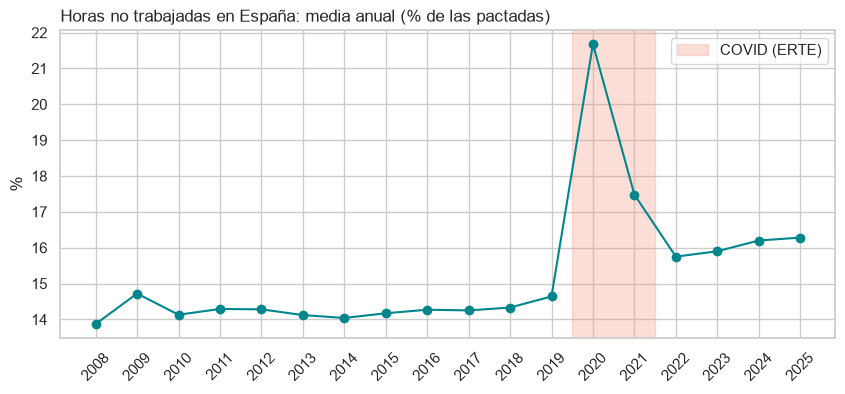

In [91]:
espana = ine[(ine["codigo_ccaa"] == 0) & (ine["sector"] == "Total")]
anual = espana.groupby("anio")["tasa_nt"].agg(["mean", "count"])
anual = anual[anual["count"] == 4]["mean"].round(2)          # solo años completos
display(anual.to_frame("horas no trabajadas (%)").T)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(anual.index, anual.values, marker="o", color=COLOR_PRINCIPAL)                      
ax.axvspan(2019.5, 2021.5, color=COLOR_DESTACADO, alpha=0.30, label="COVID (ERTE)")       
ax.set_xticks(anual.index)                                     # un año en cada marca del eje
ax.tick_params(axis="x", rotation=45)
ax.set_title("Horas no trabajadas en España: media anual (% de las pactadas)", loc="left")
ax.set_ylabel("%")
ax.legend()
plt.show()

Se observa que desde 2008 a 2019 estaban quietas, en torno al 14 %. En **2020 saltan al 21,7 %** por los ERTE (no son bajas) y en 2021 bajan. 

Desde 2022 **suben cada año** hasta el **16,3 % de 2025**, lo más alto sin contar la COVID. Pero el INE no separa la baja médica de las vacaciones o los permisos, así que lo compruebo con las bajas médicas.


Seguridad Social: las bajas médicas (2023-2025)

,iniciadas,incidencia,duracion,prevalencia
anio,,,,
2023,8150921.0,31.60,39.5,47.52
2024,8552266.0,32.29,43.1,49.29
2025,9196228.0,34.03,42.3,51.42


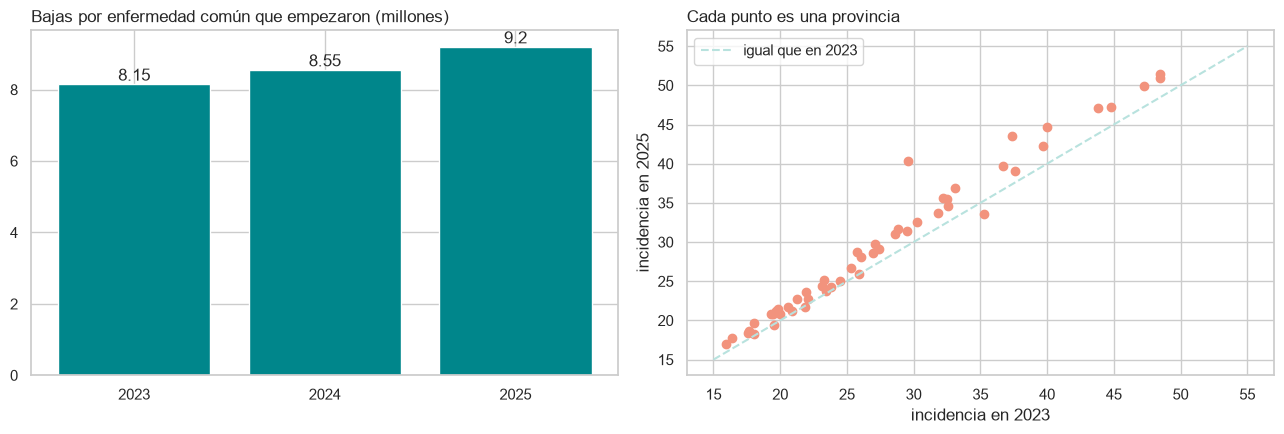

Provincias donde la incidencia de 2025 es mayor que la de 2023: 49 de 52
Subida de las bajas iniciadas en España: 12.8 %


In [92]:
comunes = it_espana[it_espana["contingencia"] == "comunes"].set_index("anio")
display(comunes[["iniciadas", "incidencia", "duracion", "prevalencia"]])

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

ejes[0].bar(comunes.index.astype(str), comunes["iniciadas"] / 1000000, color=COLOR_PRINCIPAL)            
for posicion, valor in enumerate(comunes["iniciadas"] / 1000000):
    ejes[0].text(posicion, valor + 0.1, str(round(valor, 2)), ha="center")
ejes[0].set_title("Bajas por enfermedad común que empezaron (millones)", loc="left")

provincias = it_provincias[it_provincias["contingencia"] == "comunes"].pivot(index="provincia", columns="anio", values="incidencia")
ejes[1].scatter(provincias[2023], provincias[2025], color=COLOR_DESTACADO)                                 # <- color de los puntos
ejes[1].plot([15, 55], [15, 55], color=COLOR_SUAVE, linestyle="--", label="igual que en 2023")
ejes[1].set_xlabel("incidencia en 2023")
ejes[1].set_ylabel("incidencia en 2025")
ejes[1].set_title("Cada punto es una provincia", loc="left")
ejes[1].legend()
plt.tight_layout()
plt.show()

suben = (provincias[2025] > provincias[2023]).sum()
print("Provincias donde la incidencia de 2025 es mayor que la de 2023:", suben, "de", len(provincias))
print("Subida de las bajas iniciadas en España:", round((comunes.loc[2025, "iniciadas"] / comunes.loc[2023, "iniciadas"] - 1) * 100, 1), "%")

Cada vez hay más bajas. 
Las bajas por enfermedad común pasan de **8,15 millones en 2023 a 9,20 millones en 2025** (un 12,8 % más), y la incidencia, de 31,6 a 34,0 bajas al mes por cada 1.000 trabajadores. En el scatter, casi todos los puntos están **por encima de la diagonal**: ha subido en **49 de las 52 provincias**. Ahora el INE y la Seguridad Social dicen lo mismo.

¿Hay diferencias entre comunidades y sectores?


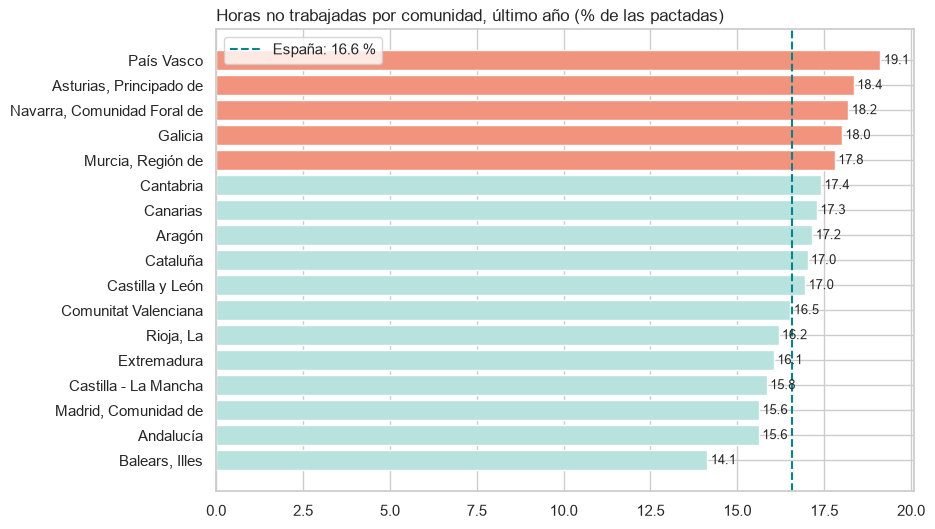

Diferencia entre la comunidad más alta y la más baja: 5.0 puntos


In [93]:
# Comunidades (último año, sector total)
ultima_fecha = ine["fecha"].max()
ultimo_anio = ine[ine["fecha"] > ultima_fecha - pd.DateOffset(months=12)]

ranking = ultimo_anio[(ultimo_anio["sector"] == "Total") & (ultimo_anio["codigo_ccaa"] > 0)].groupby("ccaa")["tasa_nt"].mean().sort_values()
media_espana = ultimo_anio[(ultimo_anio["sector"] == "Total") & (ultimo_anio["codigo_ccaa"] == 0)]["tasa_nt"].mean()

colores_barras = [COLOR_DESTACADO if valor > media_espana + 1 else COLOR_SUAVE for valor in ranking.values]


fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ranking.index, ranking.values, color=colores_barras)
ax.axvline(media_espana, color=COLOR_PRINCIPAL, linestyle="--", label="España: " + str(round(media_espana, 1)) + " %")
for posicion, valor in enumerate(ranking.values):
    ax.text(valor + 0.1, posicion, str(round(valor, 1)), va="center", fontsize=9)
ax.set_title("Horas no trabajadas por comunidad, último año (% de las pactadas)", loc="left")
ax.legend()
plt.show()

print("Diferencia entre la comunidad más alta y la más baja:", round(ranking.max() - ranking.min(), 1), "puntos")

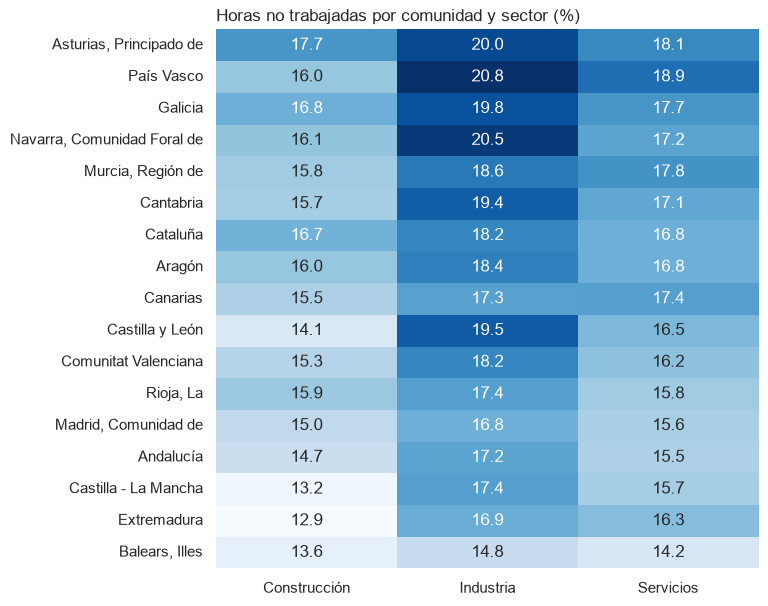

In [94]:
# Comunidad × sector ¿Se repite el patrón en todos los sectores?

cruce = ultimo_anio[(ultimo_anio["codigo_ccaa"] > 0) & (ultimo_anio["sector"] != "Total")].pivot_table(
    index="ccaa", columns="sector", values="tasa_nt")
cruce = cruce.loc[cruce.mean(axis=1).sort_values(ascending=False).index]      # ordeno de más a menos

plt.figure(figsize=(7, 7))
sns.heatmap(cruce.round(1), annot=True, fmt=".1f", cmap=MAPA_DE_CALOR, cbar=False)   # <- cmap: el degradado
# annot=True escribe el número en cada casilla; fmt=".1f" dice que lo escriba con 1 decimal
plt.title("Horas no trabajadas por comunidad y sector (%)", loc="left")
plt.ylabel("")
plt.xlabel("")
plt.show()

Si hay diferencias claras: **5 puntos** entre la que más (**País Vasco, 19,1 %**) y la que menos (**Baleares, 14,1 %**). País Vasco, Asturias, Navarra y Galicia salen arriba en los tres sectores, así que no es solo por los sectores que tiene cada comunidad.

Comunidades con bajas medicas (Seguridad Social, 2025)
Con la **tabla común**. La **prevalencia** -> cuántos trabajadores de cada 1.000 están de baja en un día cualquiera.

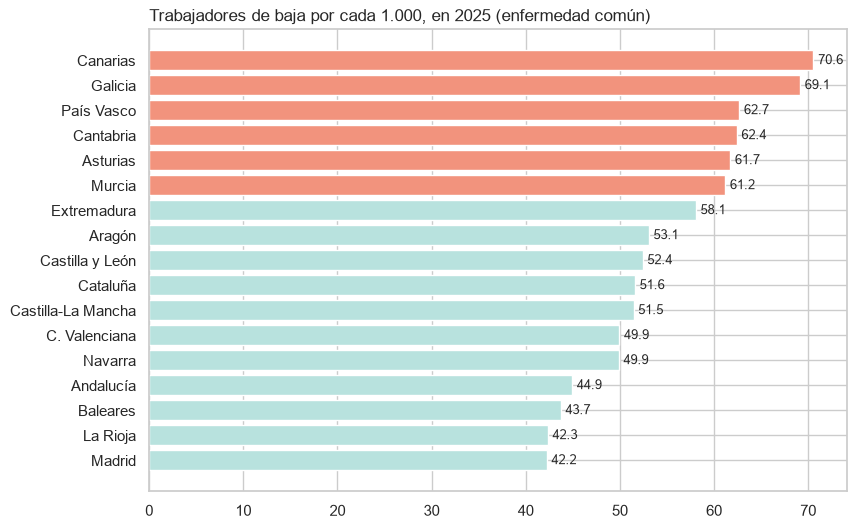

In [95]:
orden = comunidades.sort_values("prevalencia")
media = orden["prevalencia"].mean()
colores_barras = [COLOR_DESTACADO if valor > media + 5 else COLOR_SUAVE for valor in orden["prevalencia"]]


fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(orden["ccaa"], orden["prevalencia"], color=colores_barras)
for posicion, valor in enumerate(orden["prevalencia"]):
    ax.text(valor + 0.5, posicion, str(round(valor, 1)), va="center", fontsize=9)
ax.set_title("Trabajadores de baja por cada 1.000, en 2025 (enfermedad común)", loc="left")
plt.show()

En **Canarias y Galicia** hay unos **70 trabajadores de baja por cada 1.000**; en **Madrid**, 42. Casi el doble.

Hay muchas bajas cortas o pocas largas.

En el univariante vi que unas provincias tienen muchas bajas que duran poco y otras pocas que duran mucho. Grafica.

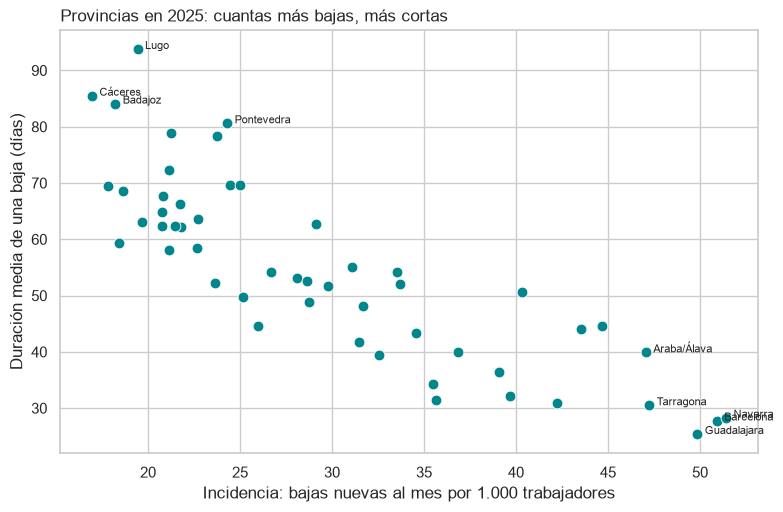

Correlación de Pearson entre incidencia y duración: -0.84


In [96]:
it_2025 = it_provincias[it_provincias["anio"] == 2025]           # solo el año 2025
it_2025 = it_2025[it_2025["contingencia"] == "comunes"]          # solo la enfermedad común

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=it_2025, x="incidencia", y="duracion", color=COLOR_PRINCIPAL, s=60, ax=ax)      # color y tamaño de los puntos
for numero_fila, fila in it_2025.iterrows():                                                         # en cada vuelta: el número de la fila y la fila entera
    if fila["incidencia"] > 45 or fila["duracion"] > 80:                                             # solo el nombre de las más extremas
        ax.text(fila["incidencia"] + 0.4, fila["duracion"], fila["provincia"].title(), fontsize=8)
ax.set_xlabel("Incidencia: bajas nuevas al mes por 1.000 trabajadores")
ax.set_ylabel("Duración media de una baja (días)")
ax.set_title("Provincias en 2025: cuantas más bajas, más cortas", loc="left")
plt.show()

print("Correlación de Pearson entre incidencia y duración:", round(it_2025["incidencia"].corr(it_2025["duracion"]), 2))

Se observa una **correlación negativa muy fuerte (−0,84)**: donde empiezan muchas bajas, duran poco (Navarra, Barcelona, Guadalajara); donde empiezan pocas, duran muchísimo (Lugo, Cáceres, Badajoz, casi tres meses). 

Este dato es sorprendente. Puede deberse a cómo se gestionan las bajas en cada sitio, a la edad de los trabajadores o al tipo de empleo **las bajas largas son las que más necesitan un plan de vuelta al trabajo**.

Sectores (España, por año)

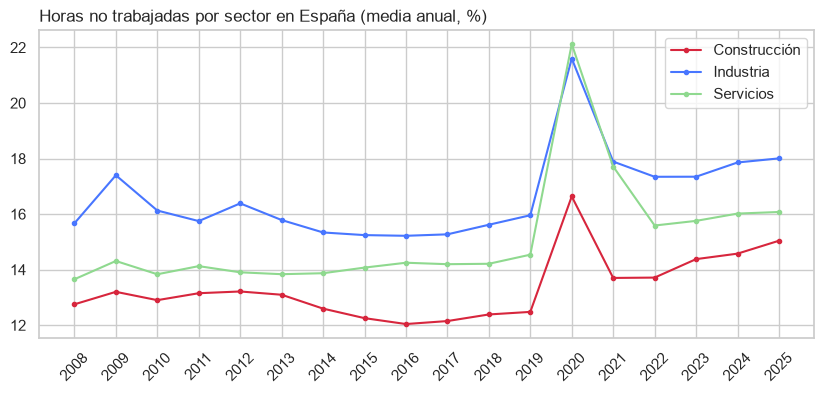

Último año completo:
sector
Industria       18.0
Servicios       16.1
Construcción    15.0
Name: 2025, dtype: float64


In [97]:
sectores = ine[(ine["codigo_ccaa"] == 0) & (ine["sector"] != "Total")]
anual_sector = sectores.groupby(["anio", "sector"])["tasa_nt"].mean().unstack()     # unstack: un sector por columna
anual_sector = anual_sector.loc[anual.index]                                        # solo años completos

fig, ax = plt.subplots(figsize=(10, 4))
for numero, sector in enumerate(anual_sector.columns):
    ax.plot(anual_sector.index, anual_sector[sector], marker=".", label=sector, color=COLORES_GRUPOS[numero])   
ax.set_xticks(anual_sector.index)
ax.tick_params(axis="x", rotation=45)
ax.set_title("Horas no trabajadas por sector en España (media anual, %)", loc="left")
ax.legend()
plt.show()

print("Último año completo:")
print(anual_sector.iloc[-1].round(1).sort_values(ascending=False))

Se observa que la **industria** es la que más horas no trabajadas tiene (18,0 % en 2025), seguida de servicios (16,1 %) y construcción (15,0 %), y pasa todos los años. 

Es sorprendente que construcción, con lo físico que es, sea la más baja; puede que influya que tiene más contratos temporales.

¿Son los sobreesfuerzos la primera causa de accidente con baja?
Tabla cruzada **sector × forma**, en % de cada sector (normalize="index" hace que cada fila sume 100)

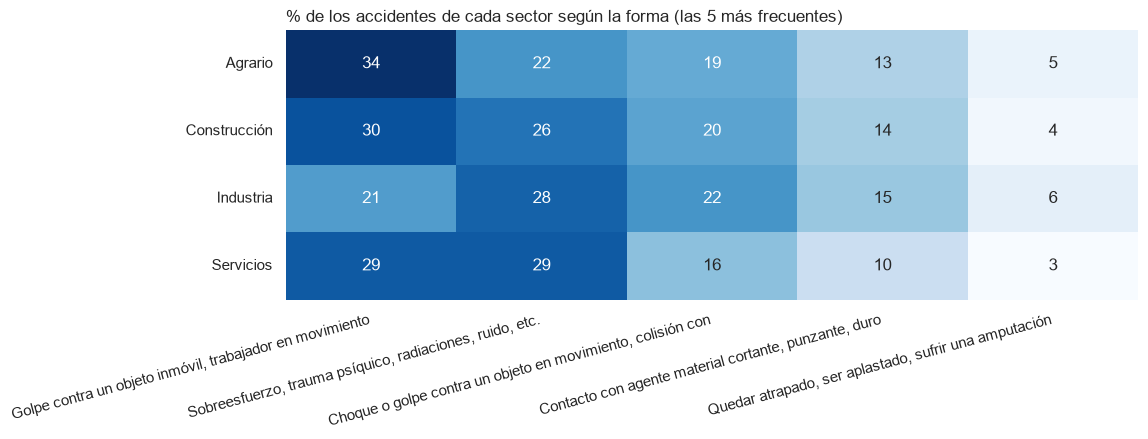

In [98]:
pct_sector = pd.crosstab(accidentes["sector"], accidentes["forma"], values=accidentes["accidentes"],
                         aggfunc="sum", normalize="index") * 100
cinco_principales = accidentes.groupby("forma")["accidentes"].sum().sort_values(ascending=False).index[:5]

plt.figure(figsize=(11, 3.5))
sns.heatmap(pct_sector[cinco_principales].round(0), annot=True, fmt=".0f", cmap=MAPA_DE_CALOR, cbar=False)   # cmap
plt.title("% de los accidentes de cada sector según la forma (las 5 más frecuentes)", loc="left")
plt.xticks(rotation=15, ha="right")
plt.ylabel("")
plt.xlabel("")
plt.show()

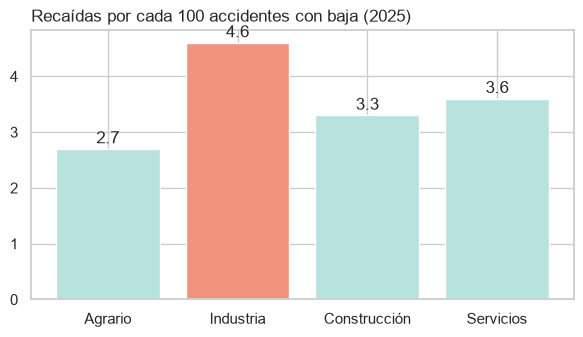

In [99]:
fig, ax = plt.subplots(figsize=(7, 3.5))
colores_barras = [COLOR_DESTACADO if s == "Industria" else COLOR_SUAVE for s in recaidas["sector"]]
ax.bar(recaidas["sector"], recaidas["tasa_recaida"], color=colores_barras)
for posicion, valor in enumerate(recaidas["tasa_recaida"]):
    ax.text(posicion, valor + 0.1, str(valor), ha="center")
ax.set_title("Recaídas por cada 100 accidentes con baja (2025)", loc="left")
plt.show()

Se observa que los sobreesfuerzos (28,0 %) son practicamente iguales que los golpes contra objetos inmóviles (28,1 %). 

Por sectores sí cambia: en la **industria** los sobreesfuerzos son la primera causa, en servicios van a la par y en el campo superan los golpes.

El sector de la industria es también en el que más **recae**: **4,6 recaídas por cada 100 accidentes**, frente a 2,7 en el campo. 

Esto demuestra que unas bajas recaen más que otras.




##### ¿Faltan más quienes tienen problemas musculoesqueléticos o de salud mental?
**Tabla cruzada** en % por fila: de la gente que tiene (o no) el problema, ¿qué % faltó?

In [100]:
for grupo in ["musculoesqueletico", "salud_mental"]:
    tabla = pd.crosstab(encuesta[grupo], encuesta["ausencia"], normalize="index") * 100
    tabla.index = ["No lo tiene", "Lo tiene"]
    tabla.columns = ["No faltó (%)", "Faltó (%)"]
    print(grupo)
    display(tabla.round(1))

musculoesqueletico


,No faltó (%),Faltó (%)
No lo tiene,79.4,20.6
Lo tiene,57.9,42.1


salud_mental


,No faltó (%),Faltó (%)
No lo tiene,77.2,22.8
Lo tiene,45.3,54.7


In [101]:
# Con los cuatro grupos (ninguno, solo musculoesquelético, solo salud mental y los dos) 
# Calculo el % que faltó y los días medios, ponderados

orden_grupos = ["Ninguno", "Musculoesquelético", "Salud mental", "Los dos"]
resumen = pd.DataFrame(index=orden_grupos)

datos = encuesta.dropna(subset=["ausencia"])
resumen["% que faltó"] = ((datos["ausencia"] * datos["peso"]).groupby(datos["grupo_salud"]).sum()
                          / datos["peso"].groupby(datos["grupo_salud"]).sum() * 100)

datos = encuesta.dropna(subset=["dias"])
resumen["días medios"] = ((datos["dias"] * datos["peso"]).groupby(datos["grupo_salud"]).sum()
                          / datos["peso"].groupby(datos["grupo_salud"]).sum())

resumen["personas"] = encuesta["grupo_salud"].value_counts()
resumen.round(1)

,% que faltó,días medios,personas
Ninguno,18.6,4.3,7012
Musculoesquelético,37.5,15.8,1921
Salud mental,50.2,26.6,413
Los dos,56.5,34.3,529


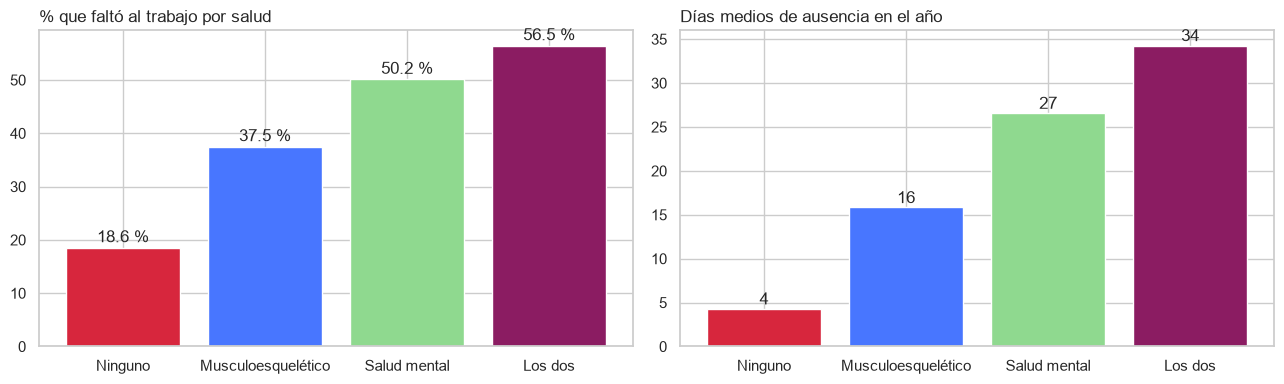

In [102]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

ejes[0].bar(resumen.index, resumen["% que faltó"], color=COLORES_GRUPOS)           
ejes[0].set_title("% que faltó al trabajo por salud", loc="left")
for posicion, valor in enumerate(resumen["% que faltó"]):
    ejes[0].text(posicion, valor + 1, str(round(valor, 1)) + " %", ha="center")

ejes[1].bar(resumen.index, resumen["días medios"], color=COLORES_GRUPOS)
ejes[1].set_title("Días medios de ausencia en el año", loc="left")
for posicion, valor in enumerate(resumen["días medios"]):
    ejes[1].text(posicion, valor + 0.5, str(round(valor)), ha="center")

plt.tight_layout()
plt.show()

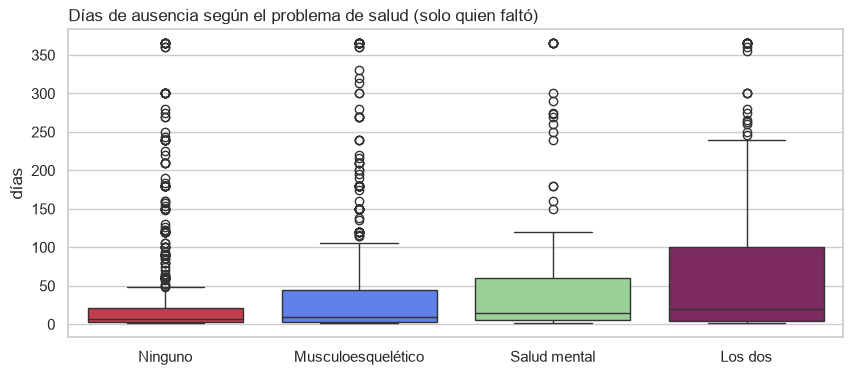

In [103]:
# Y la distribución completa de los días con un boxplot por grupos (solo quien faltó)

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=encuesta[encuesta["ausencia"] == 1], x="grupo_salud", y="dias", order=orden_grupos,
            hue="grupo_salud", palette=COLORES_GRUPOS, hue_order=orden_grupos, legend=False, ax=ax)   
ax.set_title("Días de ausencia según el problema de salud (solo quien faltó)", loc="left")
ax.set_xlabel("")
ax.set_ylabel("días")
plt.show()

Se evidencia que sin ningún problema falta el **19 %** (4 días de media en el año). 

Con un problema **musculoesquelético** falta el **38 %** (16 días). 

Con **salud mental**, el **50 %** (27 días). 

Y con **los dos a la vez**, el **56,5 %** y **34 días** de media: ocho veces más días que quien no tiene ninguno. En el boxplot se ve que no es solo la media: toda la caja está más arriba.

#### ¿Se lleva una minoría la mayoría de los días de baja?
**Curva de concentración**, paso a paso:
- Ordeno a las personas de **más a menos días**.
- Sumo el % de personas (eje X) y el % de días (eje Y), con los pesos. "cumsum()" es la suma acumulada: cada fila suma lo anterior más lo suyo.


El 1.6 % de los ocupados acumula el 50 % de los días (bajas de 150.0 días o más)
El 4.7 % de los ocupados acumula el 80 % de los días


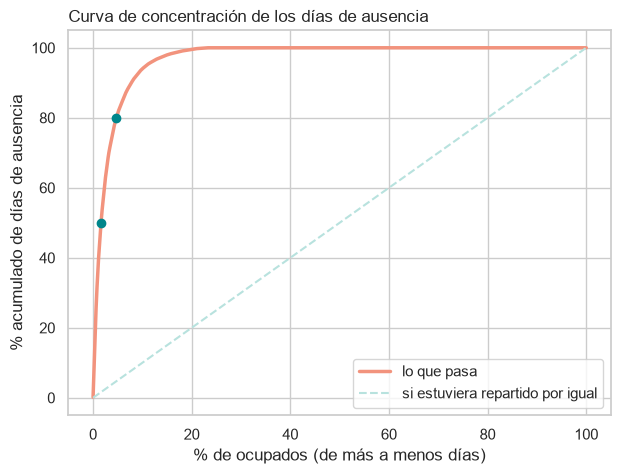

In [104]:
orden_dias = encuesta.dropna(subset=["dias"]).sort_values("dias", ascending=False).copy()
orden_dias["pct_personas"] = orden_dias["peso"].cumsum() / orden_dias["peso"].sum() * 100
orden_dias["pct_dias"] = (orden_dias["dias"] * orden_dias["peso"]).cumsum() / (orden_dias["dias"] * orden_dias["peso"]).sum() * 100

pct_mitad = orden_dias[orden_dias["pct_dias"] >= 50]["pct_personas"].iloc[0]     # la primera fila que llega al 50 % de los días
pct_80 = orden_dias[orden_dias["pct_dias"] >= 80]["pct_personas"].iloc[0]
dias_umbral = orden_dias[orden_dias["pct_dias"] >= 50]["dias"].iloc[0]
print("El", round(pct_mitad, 1), "% de los ocupados acumula el 50 % de los días (bajas de", dias_umbral, "días o más)")
print("El", round(pct_80, 1), "% de los ocupados acumula el 80 % de los días")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(orden_dias["pct_personas"], orden_dias["pct_dias"], color=COLOR_DESTACADO, linewidth=2.5, label="lo que pasa")  
ax.plot([0, 100], [0, 100], color=COLOR_SUAVE, linestyle="--", label="si estuviera repartido por igual")
ax.scatter([pct_mitad, pct_80], [50, 80], color=COLOR_PRINCIPAL, zorder=3)
ax.set_xlabel("% de ocupados (de más a menos días)")
ax.set_ylabel("% acumulado de días de ausencia")
ax.set_title("Curva de concentración de los días de ausencia", loc="left")
ax.legend()
plt.show()

In [105]:
# Para saber cual es el grupo que se lleva la mitad de los días. Comparación con el resto (% con cada problema, ponderado)

orden_dias["grupo"] = "Resto"
orden_dias.loc[orden_dias["dias"] >= dias_umbral, "grupo"] = "Se lleva el 50 % de los días"

perfil = pd.DataFrame()
for problema in ["lumbar", "cervical", "artrosis", "depresion", "ansiedad", "musculoesqueletico", "salud_mental"]:
    datos = orden_dias.dropna(subset=[problema])
    perfil[problema] = ((datos[problema] * datos["peso"]).groupby(datos["grupo"]).sum()
                        / datos["peso"].groupby(datos["grupo"]).sum() * 100)
perfil = perfil.T   # giro de tabla
perfil["veces más"] = perfil["Se lleva el 50 % de los días"] / perfil["Resto"]
perfil.round(1).sort_values("veces más", ascending=False)

grupo,Resto,Se lleva el 50 % de los días,veces más
depresion,4.3,25.4,5.9
artrosis,6.1,28.7,4.7
salud_mental,7.6,30.9,4.1
ansiedad,5.8,18.7,3.2
cervical,12.1,34.4,2.8
lumbar,15.3,39.1,2.6
musculoesqueletico,21.9,57.8,2.6


El **1,6 % de los ocupados** (bajas de 150 días o más) se lleva **la mitad** de todos los días, y menos del 5 % se lleva el 80 %.

Ese grupo tiene un perfil muy claro: la **depresión es casi 6 veces** más frecuente que en el resto, la artrosis casi 5 veces, y más de la mitad tiene algún problema musculoesquelético. 

#### Es aqui donde una intervención de reincorporación al trabajo tendría más impacto.

##### ¿Cuentan lo mismo las fuentes por comunidad?
Utilizo la **tabla común**. Comparo, comunidad a comunidad, la tasa de horas no trabajadas del INE con:
- las **bajas medicas** de la Seguridad Social (prevalencia);
- lo que **dice la gente** en la Encuesta de Salud (% que faltó por salud).

Cada punto es una comunidad.

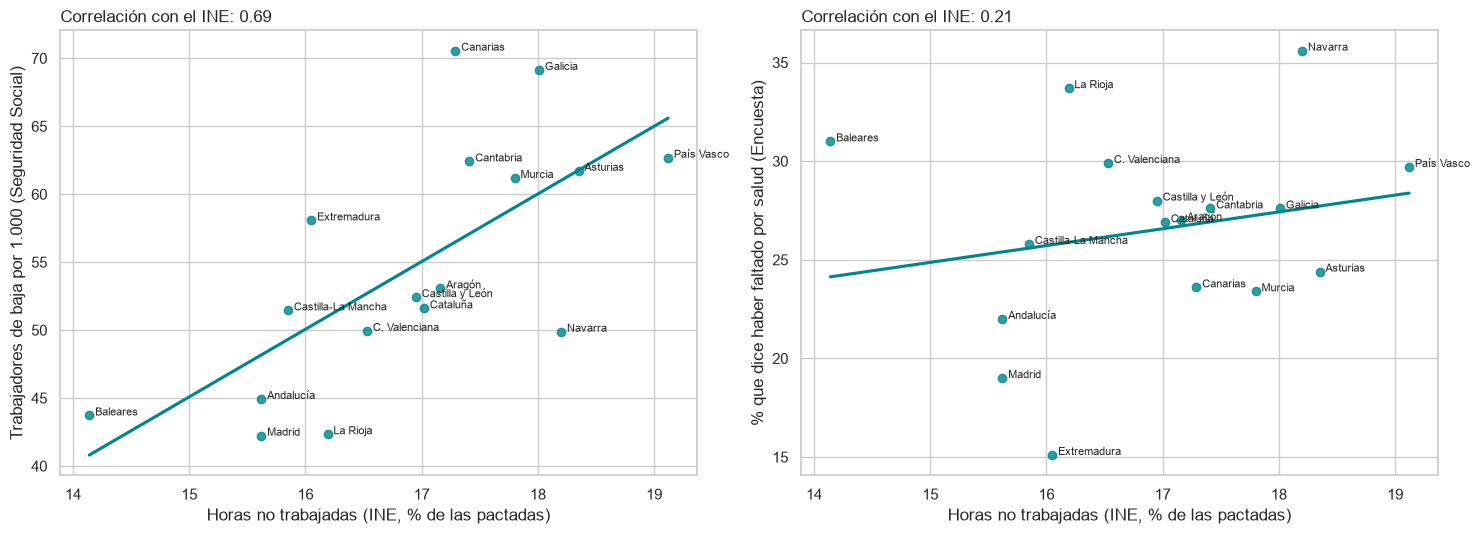

In [106]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))

parejas = [("prevalencia", "Trabajadores de baja por 1.000 (Seguridad Social)"),
           ("pct_ausencia", "% que dice haber faltado por salud (Encuesta)")]
for eje, (columna, nombre) in zip(ejes, parejas):          # zip: va cogiendo un eje y una pareja a la vez
    sns.regplot(data=comunidades, x="tasa_nt", y=columna, color=COLOR_PRINCIPAL, ci=None, ax=eje)     
    # regplot = scatter + la recta que mejor resume la tendencia; ci=None quita la sombra de alrededor
    for _, fila in comunidades.iterrows():                 # escribo el nombre al lado de cada punto
        eje.text(fila["tasa_nt"] + 0.05, fila[columna], fila["ccaa"], fontsize=8)
    r = comunidades["tasa_nt"].corr(comunidades[columna])
    eje.set_title("Correlación con el INE: " + str(round(r, 2)), loc="left")
    eje.set_xlabel("Horas no trabajadas (INE, % de las pactadas)")
    eje.set_ylabel(nombre)
plt.tight_layout()
plt.show()

El INE y la Seguridad Social **sí van juntos** (correlación de **0,69**): donde se pierden más horas, hay más trabajadores de baja. El INE aunque mezcla vacaciones y permisos, sí refleja las bajas.


En cambio la encuesta **no coincide** con ninguno de los dos (0,21 con el INE). 

La encuesta mide lo que **dice la gente** de un año concreto, con una muestra pequeña por comunidad, y las otras dos miden **registros oficiales**. 

El caso más claro es **Baleares**: de las que menos horas y bajas tiene, pero de las que más gente dice haber faltado.

##### Sexo y edad (hay relación)

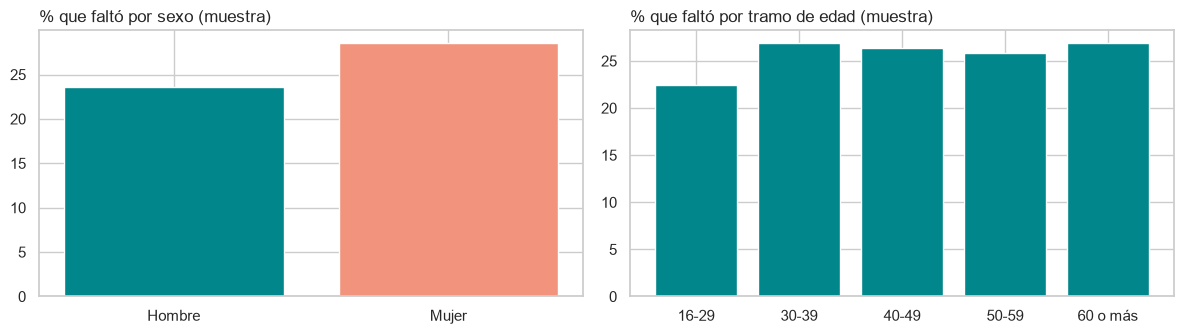

sexo
Hombre    23.6
Mujer     28.5
Name: ausencia, dtype: float64
tramo_edad
16-29       22.4
30-39       26.9
40-49       26.4
50-59       25.8
60 o más    26.9
Name: ausencia, dtype: float64


In [107]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))

por_sexo = encuesta.groupby("sexo")["ausencia"].mean() * 100
ejes[0].bar(por_sexo.index, por_sexo.values, color=[COLOR_PRINCIPAL, COLOR_DESTACADO])
ejes[0].set_title("% que faltó por sexo (muestra)", loc="left")

por_edad = encuesta.groupby("tramo_edad", observed=True)["ausencia"].mean() * 100     # observed=True: solo los tramos que existen
ejes[1].bar(por_edad.index.astype(str), por_edad.values, color=COLOR_PRINCIPAL)
ejes[1].set_title("% que faltó por tramo de edad (muestra)", loc="left")

plt.tight_layout()
plt.show()
print(por_sexo.round(1))
print(por_edad.round(1))

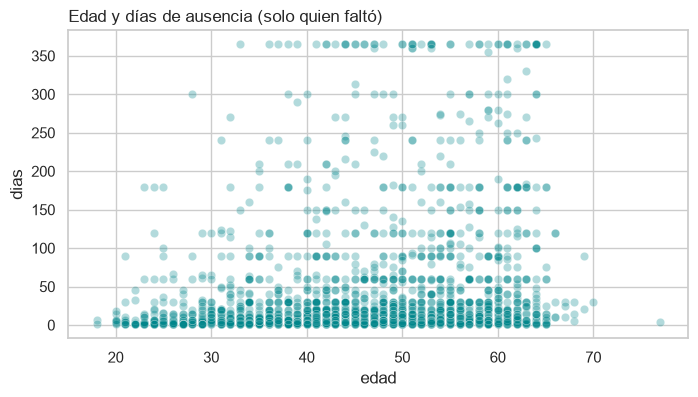

In [108]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=encuesta[encuesta["ausencia"] == 1], x="edad", y="dias", alpha=0.3, color=COLOR_PRINCIPAL, ax=ax)   # <- alpha: transparencia
ax.set_title("Edad y días de ausencia (solo quien faltó)", loc="left")
plt.show()

Se observa que las mujeres faltan algo más que los hombres. Por edad casi no hay diferencias, salvo los menores de 30, que faltan menos. Y en el scatter la nube no tiene forma: la edad por si sola **no explica** los días de baja.

## Análisis multivariante

Matriz de correlación (Pearson): días, edad y problemas de salud

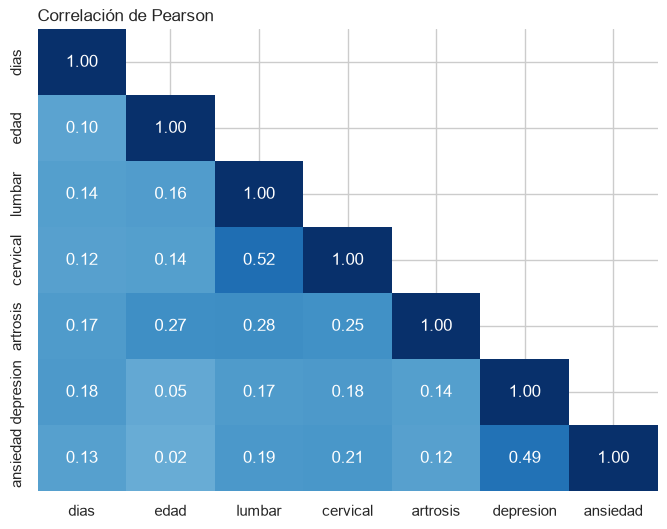

In [110]:
columnas = ["dias", "edad", "lumbar", "cervical", "artrosis", "depresion", "ansiedad"]
correlacion = encuesta[columnas].corr(method="pearson")

mascara = np.triu(np.ones_like(correlacion, dtype=bool), k=1)     # True en la mitad de arriba
                                                                  # la máscara tapa la mitad de arriba, porque es igual que la de abajo.
plt.figure(figsize=(8, 6))
sns.heatmap(correlacion.round(2), mask=mascara, annot=True, fmt=".2f",
            cmap="Blues", center=0, vmin=-1, vmax=1, cbar=False)        
plt.title("Correlación de Pearson", loc="left")
plt.show()


- La primera columna (dias) evidencia qué se relaciona más con los días de ausencia.
- Las casillas entre problemas de salud muestran cuáles suelen ir juntos.
- Valores de 0,1 o 0,2 son normales con datos de personas: **las personas somos muy distintas e impredecibles** y ninguna variable sola lo explica todo.

Lo que más se relaciona con los días es la **depresión** (0,18) y la **artrosis** (0,17), seguido del dolor lumbar. Son correlaciones pequeñas: cada cosa suma, pero ninguna explica sola los días de baja.

Lo más fuerte son las parejas de problemas: **lumbar y cervical (0,52)** y **depresión y ansiedad (0,49)** suelen ir juntos. 


Spearman

Pearson mira relaciones en **línea recta** y le afectan mucho los valores extremos (como las bajas de 365 días). **Spearman** usa el **orden** de los datos en vez de los valores, así que aguanta mejor los extremos. 

In [111]:
comparacion = pd.DataFrame({
    "Pearson": encuesta[columnas].corr(method="pearson")["dias"],
    "Spearman": encuesta[columnas].corr(method="spearman")["dias"],
}).drop("dias")
comparacion.round(2).sort_values("Spearman", ascending=False)

,Pearson,Spearman
lumbar,0.14,0.18
ansiedad,0.13,0.17
depresion,0.18,0.17
artrosis,0.17,0.15
cervical,0.12,0.15
edad,0.10,0.02


Reflejan casi lo mismo para las enfermedades. Con la edad, Spearman baja a casi 0: lo poco que salía con Pearson era por unos pocos casos extremos.

##### Tabla común.
Una fila por comunidad y en columnas -> lo que dice cada fuente:
- **INE:** tasa_nt (horas no trabajadas);
- **Seguridad Social:** incidencia, duracion y prevalencia de las bajas;
- **Encuesta:** pct_ausencia (% que faltó), dias_medios, pct_musculoesqueletico y pct_salud_mental.


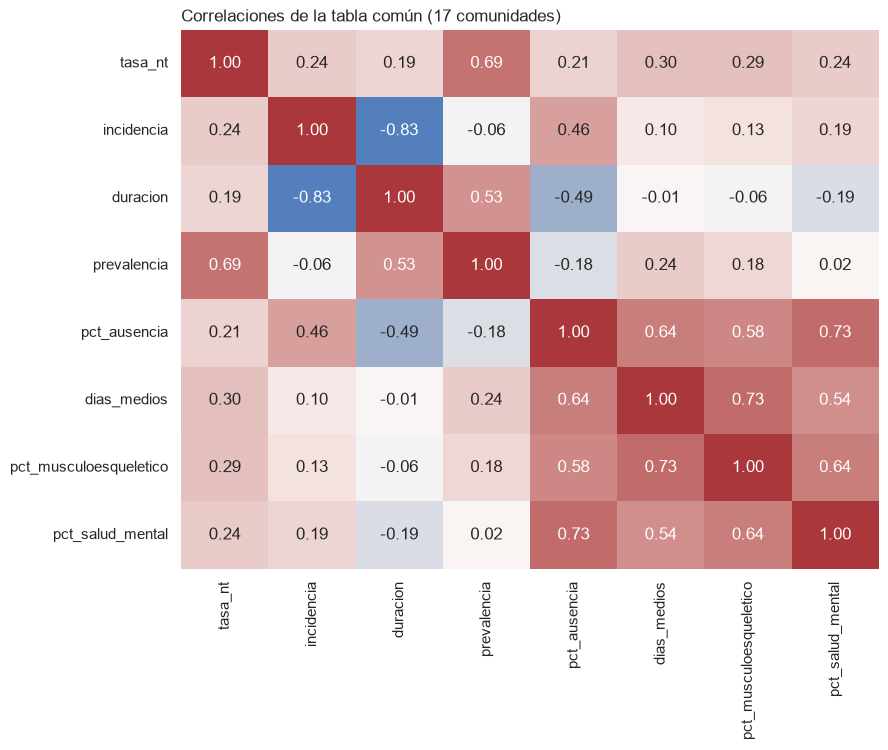

In [117]:
# heatmap con todas las correlaciones
medidas = ["tasa_nt", "incidencia", "duracion", "prevalencia", "pct_ausencia", "dias_medios",
           "pct_musculoesqueletico", "pct_salud_mental"]
correlacion_ccaa = comunidades[medidas].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlacion_ccaa.round(2), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, cbar=False)   
plt.title("Correlaciones de la tabla común (17 comunidades)", loc="left")
plt.show()

Se observa que:
- **INE y Seguridad Social van juntos:** tasa de horas no trabajadas y prevalencia de bajas, **0,69**.
- **Incidencia y duración, al revés (−0,83):** las comunidades con muchas bajas las tienen cortas.
- **La Encuesta va por su lado:** su % de ausencia no se relaciona con la prevalencia oficial (−0,18), pero **dentro de la encuesta** sí hay relaciones fuertes: donde hay más gente con **salud mental** se falta más (0,73), y donde hay más problemas **musculoesqueléticos** se acumulan más días (0,73).



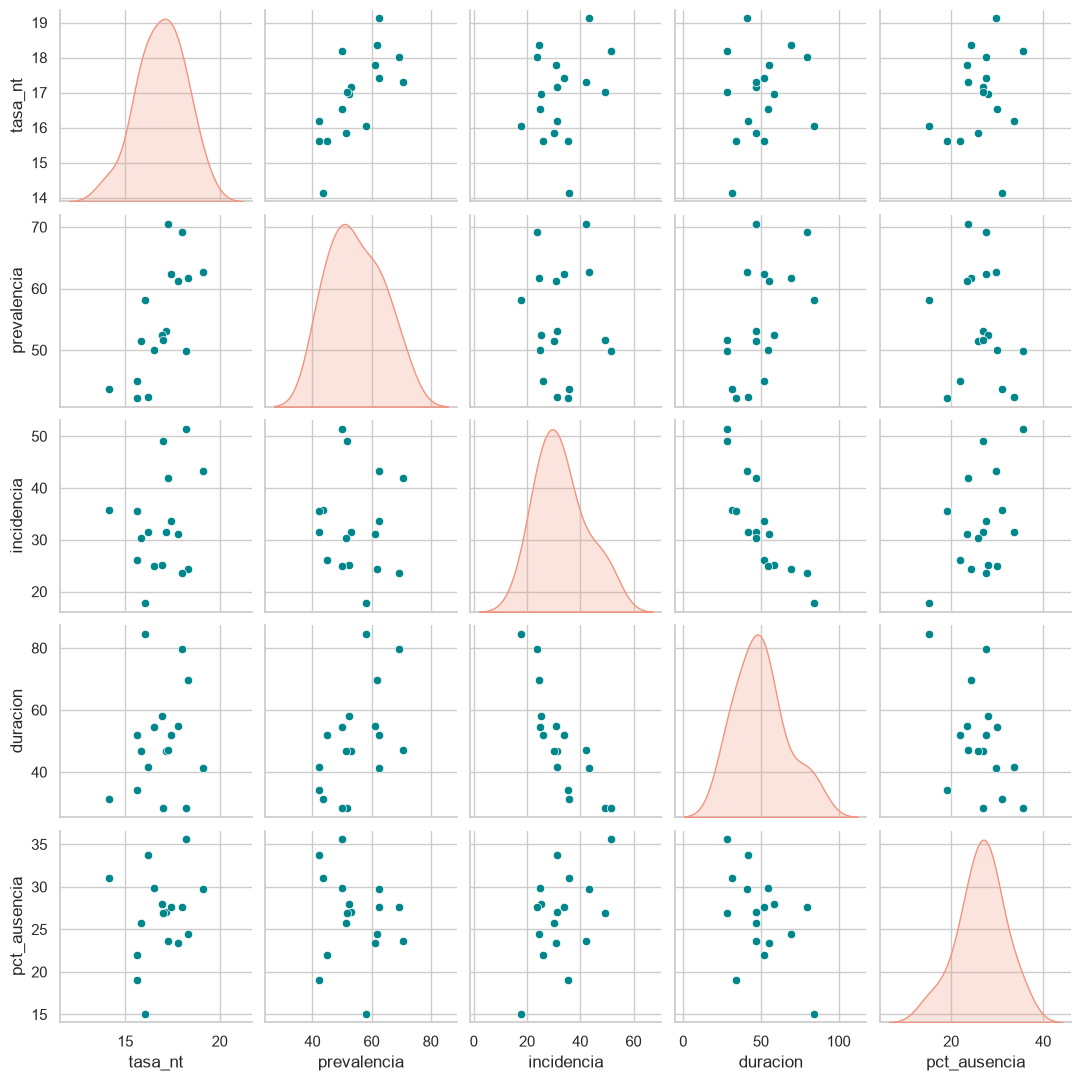

In [118]:
# pairplot, con las cinco medidas principales

principales = ["tasa_nt", "prevalencia", "incidencia", "duracion", "pct_ausencia"]

sns.pairplot(comunidades[principales], diag_kind="kde", height=2.2,
             plot_kws={"color": COLOR_PRINCIPAL}, diag_kws={"color": COLOR_DESTACADO})  
plt.show()


Con las tres fuentes "escaladas"


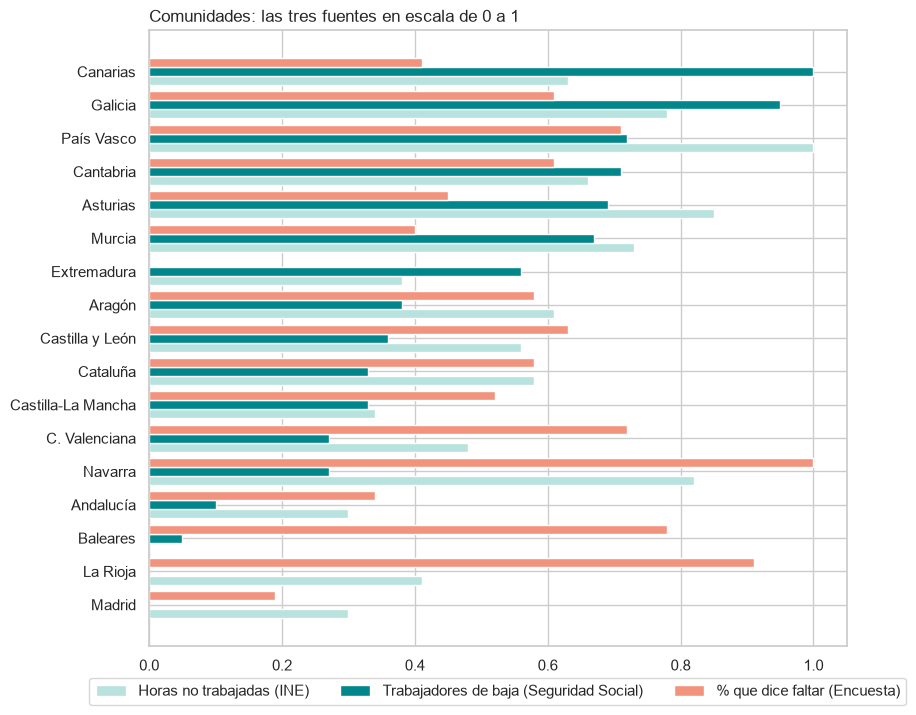

In [119]:
orden = comunidades.sort_values("prevalencia_0a1")

fig, ax = plt.subplots(figsize=(9, 8))
posiciones = np.arange(len(orden))
ax.barh(posiciones - 0.27, orden["tasa_nt_0a1"], height=0.27, color=COLOR_SUAVE, label="Horas no trabajadas (INE)")             
ax.barh(posiciones, orden["prevalencia_0a1"], height=0.27, color=COLOR_PRINCIPAL, label="Trabajadores de baja (Seguridad Social)")  
ax.barh(posiciones + 0.27, orden["pct_ausencia_0a1"], height=0.27, color=COLOR_DESTACADO, label="% que dice faltar (Encuesta)")   
ax.set_yticks(posiciones)
ax.set_yticklabels(orden["ccaa"])
ax.set_title("Comunidades: las tres fuentes en escala de 0 a 1", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=3)      # la leyenda debajo
plt.show()

En resumen, el anáisis multivariante, muestra que:
- Lo que más se relaciona con los días de ausencia es la **depresión** y lo **musculoesquelético**, con correlaciones pequeñas: nada lo explica todo solo, porque las personas son muy distintas.
- Hay problemas que **van juntos**: lumbar y cervical (0,52), depresión y ansiedad (0,49).
- La edad casi no influye (0,10 con Pearson y casi 0 con Spearman).
- En la tabla común, el INE y la Seguridad Social van juntos (0,69) y la Encuesta va por otro lado.
- Donde hay muchas bajas, son cortas; donde hay pocas, largas (−0,83).


# Contraste de hipótesis

Test estadísticos

#### Pearson ¿Suben las horas no trabajadas con los años?
Años completos desde 2015.

In [121]:
from scipy import stats      # tests estadísticos (Pearson)


In [124]:
# Solo el Total Nacional y el sector Total
espana = ine[ine["codigo_ccaa"] == 0]
espana = espana[espana["sector"] == "Total"]

# Media de cada año y cuántos trimestres tiene
anual = espana.groupby("anio")["tasa_nt"].agg(["mean", "count"])
anual = anual[anual["count"] == 4]          # solo años completos (4 trimestres)
anual = anual[anual.index >= 2015]          # desde 2015
anual = anual["mean"]

# 1) Pearson con todos los años desde 2015
r, p = stats.pearsonr(anual.index, anual.values)
if p < 0.001:
    print("Desde 2015 (con la COVID): r =", round(r, 2), "| p < 0,001")
else:
    print("Desde 2015 (con la COVID): r =", round(r, 2), "| p =", round(p, 3))

# 2) Pearson sin los años de la COVID
sin_covid = anual.drop([2020, 2021])
r, p = stats.pearsonr(sin_covid.index, sin_covid.values)
if p < 0.001:
    print("Sin 2020 y 2021 (COVID): r =", round(r, 2), "| p < 0,001")
else:
    print("Sin 2020 y 2021 (COVID): r =", round(r, 2), "| p =", round(p, 3))

Desde 2015 (con la COVID): r = 0.39 | p = 0.229
Sin 2020 y 2021 (COVID): r = 0.98 | p < 0,001


Teniendo en cuenta todos los años **no sale significativo** (p mayor que 0,05) a tener en cuenta el pico de los ERTE de 2020. 

Quitando 2020 y 2021, la subida es casi perfecta (**r = 0,98**) y significativa. 


In [126]:
# La incidencia de las bajas es igual en 2023 que en 2025

provincias = it_provincias[it_provincias["contingencia"] == "comunes"].pivot(index="provincia", columns="anio", values="incidencia")
w, p = stats.wilcoxon(provincias[2023], provincias[2025])
suben = (provincias[2025] > provincias[2023]).mean()
print("Incidencia media de las provincias: 2023 =", round(provincias[2023].mean(), 1), "| 2025 =", round(provincias[2025].mean(), 1))

Incidencia media de las provincias: 2023 = 27.7 | 2025 = 29.6


Es **Significativo** (p < 0,001): la subida de las bajas no es casualidad. 

Ha subido en el 94 % de las provincias.

#### Kruskal-Wallis ¿Son distintas las comunidades y los sectores?
Para quitar el efecto de las vacaciones, comparo cada comunidad con **la media de España en el mismo trimestre** (últimos 12 trimestres).

In [ ]:
# 1) Solo el sector Total y los últimos 3 años (36 meses)
ultima_fecha = ine["fecha"].max()                                   # el último trimestre que hay
desde = ultima_fecha - pd.DateOffset(months=36)                     # 36 meses antes
reciente = ine[ine["sector"] == "Total"]
reciente = reciente[reciente["fecha"] > desde]

# 2) La media de España de cada trimestre, en una columna aparte
nacional = reciente[reciente["codigo_ccaa"] == 0][["fecha", "tasa_nt"]]
nacional = nacional.rename(columns={"tasa_nt": "tasa_espana"})

# 3) Cada comunidad, con la media de España del mismo trimestre al lado
por_ccaa = reciente[reciente["codigo_ccaa"] > 0]
por_ccaa = por_ccaa.merge(nacional, on="fecha")
por_ccaa["diferencia"] = por_ccaa["tasa_nt"] - por_ccaa["tasa_espana"]     # cuánto está por encima o por debajo de España

# 4) Un grupo por comunidad: la lista de sus diferencias
grupos = []
for comunidad in por_ccaa["ccaa"].unique():                         # recorro las comunidades una a una
    datos = por_ccaa[por_ccaa["ccaa"] == comunidad]                 # las filas de esa comunidad
    grupos.append(datos["diferencia"])                              # y guardo sus diferencias en la lista

# 5) Test de Kruskal-Wallis y tamaño del efecto
h, p = stats.kruskal(*grupos)                                       # el * pasa cada comunidad como un grupo distinto
epsilon2 = (h - len(grupos) + 1) / (len(por_ccaa) - len(grupos))    

if p < 0.001:
    print("Comunidades: H =", round(h, 1), "| p < 0,001 | épsilon² =", round(epsilon2, 2))
else:
    print("Comunidades: H =", round(h, 1), "| p =", round(p, 3), "| épsilon² =", round(epsilon2, 2))

Comunidades: H = 104.5 | p < 0,001 | épsilon² = 0.47


In [128]:
# 1) Solo el último año (12 meses), las comunidades y los tres sectores
ultima_fecha = ine["fecha"].max()                                   # el último trimestre que hay
desde = ultima_fecha - pd.DateOffset(months=12)                     # 12 meses antes
ultimo_anio = ine[ine["fecha"] > desde]                             # los últimos 4 trimestres
ultimo_anio = ultimo_anio[ultimo_anio["codigo_ccaa"] > 0]           # solo comunidades (sin el Total Nacional)
ultimo_anio = ultimo_anio[ultimo_anio["sector"] != "Total"]         # solo Industria, Construcción y Servicios

# 2) Un grupo por sector: la lista de sus tasas
grupos = []
for sector in ultimo_anio["sector"].unique():                       # recorro los sectores uno a uno
    datos = ultimo_anio[ultimo_anio["sector"] == sector]            # las filas de ese sector
    grupos.append(datos["tasa_nt"])                                 # y guardo sus tasas en la lista

# 3) Test de Kruskal-Wallis y tamaño del efecto
h, p = stats.kruskal(*grupos)                                       # el * pasa cada sector como un grupo distinto
epsilon2 = (h - len(grupos) + 1) / (len(ultimo_anio) - len(grupos)) 

if p < 0.001:
    print("Sectores: H =", round(h, 1), "| p < 0,001 | épsilon² =", round(epsilon2, 2))
else:
    print("Sectores: H =", round(h, 1), "| p =", round(p, 3), "| épsilon² =", round(epsilon2, 2))

Sectores: H = 20.7 | p < 0,001 | épsilon² = 0.09


Son **significativas** (p es mucho menor que 0,05). Entre comunidades el efecto es **grande** 

No es casualidad.


-->   Sectores: H = 20.7 | p < 0,001 | épsilon² = 0.09

A tener en cuenta también que la estadística de accidentes recoge **todos** los accidentes con baja de 2025, no una muestra. Así que no hay casualidad que descartar: los porcentajes son el dato real. 

Sobreesfuerzos 28,0 % y golpes contra objetos 28,1 %: **igualados**. 

En industria, los sobreesfuerzos sí son la primera causa, y la industria es la que más recae (4,6 por cada 100).

#### Chi-cuadrado y Mann-Whitney



**Chi-cuadrado:** compruebo si faltar al trabajo tiene que ver con tener cada problema de salud.

- ¿Faltar al trabajo no tiene nada que ver con tener el problema de salud?
- Si el **p-valor es menor que 0,05** la relación no es casualidad.

pd.crosstab hace la tabla de cuántas personas hay en cada combinación (tiene o no el problema × faltó o no) y stats.chi2_contingency hace el test.

La **V de Cramér** es el tamaño del efecto: dice cuánto importa la relación. Va de 0 a 1: alrededor de 0,1 es pequeño, 0,3 moderado y 0,5 grande.

In [131]:
for problema in ["lumbar", "cervical", "artrosis", "depresion", "ansiedad", "musculoesqueletico", "salud_mental"]:
    datos = encuesta.dropna(subset=["ausencia", problema])                       # quito quien no tiene dato en alguna de las dos
    tabla = pd.crosstab(datos[problema], datos["ausencia"])                      # tabla cruzada: tiene o no el problema x faltó o no
    chi2, p, grados_libertad, esperados = stats.chi2_contingency(tabla)          # test de chi-cuadrado
    v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))     # tamaño del efecto (V de Cramér)

    if p < 0.001:
        print(problema, "-> chi² =", round(chi2, 1), "| p < 0,001 | V de Cramér =", round(v_cramer, 2))
    else:
        print(problema, "-> chi² =", round(chi2, 1), "| p =", round(p, 3), "| V de Cramér =", round(v_cramer, 2))



lumbar -> chi² = 337.1 | p < 0,001 | V de Cramér = 0.19
cervical -> chi² = 240.5 | p < 0,001 | V de Cramér = 0.16
artrosis -> chi² = 176.5 | p < 0,001 | V de Cramér = 0.14
depresion -> chi² = 312.5 | p < 0,001 | V de Cramér = 0.18
ansiedad -> chi² = 302.6 | p < 0,001 | V de Cramér = 0.18
musculoesqueletico -> chi² = 436.7 | p < 0,001 | V de Cramér = 0.21
salud_mental -> chi² = 443.7 | p < 0,001 | V de Cramér = 0.21


En todos los problemas el p-valor es menor que 0,001 -> demuestra que tener problemas de espalda o de salud mental **sí** tiene que ver con faltar al trabajo. La V de Cramér es pequeña-moderada (alrededor de 0,2): influyen, pero no lo explican todo solos.

**Mann-Whitney:** compruebo si quien tiene problemas musculoesqueléticos o de salud mental falta más días al trabajo.


Uso Mann-Whitney y no la t de Student porque los días no siguen una distribución normal: casi todos faltan poco y unos pocos faltan muchísimo. El **efecto** (correlación biserial por rangos) dice cuánto importa la diferencia.

In [132]:
for grupo in ["musculoesqueletico", "salud_mental"]:
    datos = encuesta.dropna(subset=["dias", grupo])                       # quito quien no tiene dato en alguna de las dos
    con_problema = datos[datos[grupo] == 1]["dias"]                       # días de quien tiene el problema
    sin_problema = datos[datos[grupo] == 0]["dias"]                       # días de quien no lo tiene
    u, p = stats.mannwhitneyu(con_problema, sin_problema)                 # test de Mann-Whitney
    efecto = 2 * u / (len(con_problema) * len(sin_problema)) - 1          # tamaño del efecto (correlación biserial por rangos)

    if p < 0.001:
        print(grupo, "-> días medios:", round(con_problema.mean(), 1), "frente a", round(sin_problema.mean(), 1),
              "| p < 0,001 | efecto =", round(efecto, 2))
    else:
        print(grupo, "-> días medios:", round(con_problema.mean(), 1), "frente a", round(sin_problema.mean(), 1),
              "| p =", round(p, 3), "| efecto =", round(efecto, 2))

musculoesqueletico -> días medios: 21.2 frente a 6.1 | p < 0,001 | efecto = 0.21
salud_mental -> días medios: 32.7 frente a 7.5 | p < 0,001 | efecto = 0.32


**Kruskal-Wallis con los cuatro grupos** (ninguno, musculoesquelético, salud mental y los dos):

In [133]:
datos = encuesta.dropna(subset=["dias"])                            # quito quien no tiene dato de días

# Un grupo por cada grupo de salud: la lista de sus días
grupos = []
for grupo in datos["grupo_salud"].unique():                          # Ninguno, Musculoesquelético, Salud mental y Los dos
    filas = datos[datos["grupo_salud"] == grupo]                     # las personas de ese grupo
    grupos.append(filas["dias"])                                     # y guardo sus días en la lista

# Test de Kruskal-Wallis y tamaño del efecto
h, p = stats.kruskal(*grupos)                                        # el * pasa cada grupo por separado
epsilon2 = (h - len(grupos) + 1) / (len(datos) - len(grupos))      

if p < 0.001:
    print("H =", round(h, 1), "| p < 0,001 | épsilon² =", round(epsilon2, 2))
else:
    print("H =", round(h, 1), "| p =", round(p, 3), "| épsilon² =", round(epsilon2, 2))

H = 689.3 | p < 0,001 | épsilon² = 0.07


Es  **significativo** (p < 0,001): tener estos problemas va unido a faltar más y más días, y no es casualidad. Pero el **efecto es pequeño-moderado** (V de Cramér en torno a 0,2): importan, pero no lo explican todo. Las personas somos muy distintas.

A tener en cuenta, que la curva de concentración describe cómo se reparten los días: el **1,6 %** de los ocupados se lleva **la mitad** de los días. 

Es una descripción, no una comparación entre grupos.



#### Pearson en la tabla común (17 comunidades)


In [137]:
# Pruebo con tres parejas si las dos medidas tienen o no relación
parejas = [("tasa_nt", "prevalencia", "Pearson: INE y Seguridad Social por comunidad"),
           ("tasa_nt", "pct_ausencia", "Pearson: INE y Encuesta por comunidad"),
           ("incidencia", "duracion", "Pearson: incidencia y duración de las bajas")]

for x, y, nombre in parejas:                                      # en cada vuelta: las dos columnas y el nombre
    r, p = stats.pearsonr(comunidades[x], comunidades[y])         # correlación de Pearson entre las dos columnas
    if p < 0.001:
        print(nombre, "-> r =", round(r, 2), "| p < 0,001")
    else:
        print(nombre, "-> r =", round(r, 2), "| p =", round(p, 3))

Pearson: INE y Seguridad Social por comunidad -> r = 0.69 | p = 0.002
Pearson: INE y Encuesta por comunidad -> r = 0.21 | p = 0.421
Pearson: incidencia y duración de las bajas -> r = -0.83 | p < 0,001


- **INE y Seguridad Social: r = 0,69, p = 0,002** → significativo y efecto grande. Las dos fuentes oficiales cuentan lo mismo.

- **INE y Encuesta: r = 0,21, p = 0,42** → no significativo. La encuesta no coincide.

- **Incidencia y duración: r = −0,83, p < 0,001** → muchas bajas cortas o pocas largas, y no es casualidad.

#### Edad y días
#### «significativo pero sin importancia»

In [139]:
datos = encuesta.dropna(subset=["edad", "dias"])                 # quito quien no tiene dato de edad o de días
r, p = stats.pearsonr(datos["edad"], datos["dias"])              # correlación de Pearson entre la edad y los días
if p < 0.001:
    print("r =", round(r, 2), "| p < 0,001")
else:
    print("r =", round(r, 2), "| p =", round(p, 3))

# r = 0.1 | p < 0,001: es significativo, pero el efecto es mínimo

r = 0.1 | p < 0,001


### Las faltas por salud se concentran en un grupo muy pequeño con bajas largas, con un perfil claro (problemas musculoesqueléticos y de salud mental, muchas veces juntos), y en sectores y comunidades concretos.

¿Cuánto se podría ahorrar? 
Si las bajas costaron unos **18.413 millones de euros** en 2025 y quienes repiten baja generan el **64,5 %** de los días (estudio del Ivie y Umivale Activa con datos de la Seguridad Social), reducir un poco los días de ese grupo ya supone mucho dinero.

In [140]:
# es un escenario
gasto_millones = 18413
peso_de_quien_repite = 0.645

escenarios = pd.DataFrame({"Se reducen sus días de baja un": ["5 %", "10 %", "20 %"]})
escenarios["Se ahorraria al año (millones de euros)"] = [round(gasto_millones * peso_de_quien_repite * reduccion)
                                                    for reduccion in [0.05, 0.10, 0.20]]
escenarios

,Se reducen sus días de baja un,Se ahorraria al año (millones de euros)
0,5 %,594
1,10 %,1188
2,20 %,2375


## Conclusiones

1. **Cada vez hay más bajas:** 9,2 millones por enfermedad común en 2025, un 12,8 % más que en 2023, y **1 de cada 4 ocupados** dice haber faltado por salud en el último año.

2. Está **muy concentrado**: el **1,6 %** de los ocupados se lleva **la mitad** de los días de ausencia.

3. Ese grupo tiene un **perfil claro**: problemas musculoesqueléticos y de salud mental, muchas veces juntos.

4. Actuar a tiempo con ese grupo es donde más se puede ahorrar. Con la **Radiografía Laboral**, los datos dicen a quién y dónde actuar antes.